# **Lab 2 – Tidying, Cleaning, Imputation, and Outlier Detection**

## Machine Learning Programming

This assignment continues the work started in **`week5Lab.ipynb`**.  
Open this notebook and complete the activities **in this notebook**, preserving the section order and the overall structure.

The purpose of this lab is to practice the data-preprocessing work that normally takes place before machine learning: reshaping data, cleaning inconsistent values, handling missing data, detecting outliers, visualizing results, and explaining the decisions you make.

## **Assignment Overview**

### Purpose
By the end of this lab, you should be able to take several imperfect datasets and make them more suitable for analysis and later machine-learning work.

### Learning Outcomes
You will practice how to:

- inspect the shape, columns, data types, and quality of a dataset;
- distinguish **wide** and **long/tidy** data;
- reshape data with `pd.melt()` or `DataFrame.melt()`;
- clean strings using Pandas string methods;
- identify, quantify, drop, and impute missing values;
- compare mean, median, mode, and `SimpleImputer` approaches;
- identify outliers visually with box plots and scatter plots;
- identify outliers statistically using **Z-Scores** and **IQR**;
- justify preprocessing decisions using evidence from the data;
- document a reproducible Python data-processing workflow.

### Estimated Completion Time
Approximately **2.5–3.5 hours**, depending on your Python experience.

## **Submission and Project Structure**

Keep the project organized so another person can reproduce your work.

Recommended structure:

```text
project/
├── week5Lab.ipynb
├── README.md
├── requirements.txt
├── .gitignore
└── data/
    ├── pew-raw.csv
    ├── billboard.csv
    ├── cars.csv
    └── diabetes.csv
```

A clearly named equivalent data folder such as `CSVs/` or `datasets/` is also acceptable if all notebook paths are updated consistently.

### Required submission artifacts

- `week5Lab.ipynb` containing **all four completed sections**
- `README.md` with at least 1–2 meaningful sentences describing the lab and how to run it
- `requirements.txt` containing the packages required to reproduce the environment
- `.gitignore`
- all required data files inside a clearly named data folder

**Important:** Use relative paths such as `./data/cars.csv`. Do not use absolute paths from your own computer.

**Environment practice:** Use `requirements.txt` to define the environment. Do not add `!pip install ...` cells to the notebook when a requirements file is provided.

## **Before You Begin**

Use the following libraries where appropriate:

- `pandas`
- `numpy`
- `matplotlib`
- `seaborn`
- `scikit-learn`

Run the import cell below before beginning the exercises.

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer

# Optional display settings
pd.set_option("display.max_columns", None)

## **General Expectations**

For every section:

1. Write the required Python code.
2. Display enough output to demonstrate that the code works.
3. Add short Markdown explanations in your own words.
4. Label plots clearly with a title and axis labels.
5. Explain what the output means instead of only producing it.
6. Preserve the required section headings so the notebook is easy to follow.
7. Before submitting, restart the kernel and use **Run All** to confirm the notebook executes from beginning to end.

### Replicability Testing

Our group used a shared GitHub repository to collaborate on this assignment. Team members cloned the repository and used `requirements.txt` to install the necessary dependencies on their computers.

The testing process and results are documented in the **Replicability Check** section at the end of this notebook.

# **Section 1 – PEW Research Dataset**

## **Learning Topic: Data Tidying and Reshaping**

A dataset is commonly described as **tidy** when:

1. each variable forms a column;
2. each observation forms a row; and
3. each type of observational unit forms a table.

The PEW dataset represents counts for religions across income ranges. In its original form, income values appear as column headings. You will reshape the dataset from **wide** format to **long/tidy** format using `melt()`.

### Required concepts
- dataset inspection
- wide versus long data
- identifier variables
- measured variables
- `pd.melt()` or `DataFrame.melt()`
- visualization after reshaping

## **Getting the PEW Dataset from the Internet**

For this lab, use the small **PEW religion-and-income dataset** commonly used to demonstrate tidy-data principles. This is the dataset whose first column is `religion` and whose remaining columns are income ranges such as `<$10k`, `$10-20k`, and `$20-30k`.

### Recommended method — download in your browser

1. Open the dataset in a browser:
   `https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv`
2. Save the file as **`pew-raw.csv`**.
3. Create a folder named **`data`** in the same project folder as this notebook if it does not already exist.
4. Move `pew-raw.csv` into the `data` folder.
5. Confirm that your project contains:

```text
project/
├── week5Lab.ipynb
└── data/
    └── pew-raw.csv
```

6. Load the local copy with:

```python
df_pew = pd.read_csv("./data/pew-raw.csv")
```

### Optional Python-assisted download

The following is an example only. You may use it once to obtain the dataset, but your submitted analysis should subsequently read the **local copy** from `./data/`.

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/nickhould/tidy-data-python/master/data/pew-raw.csv"
df_pew = pd.read_csv(url)
df_pew.to_csv("./data/pew-raw.csv", index=False)
```

### Verify before continuing

After loading the file, check that the dataframe contains a `religion` column and multiple income-range columns. If it does not, stop and verify that you downloaded the correct dataset.

> **Good reproducibility practice:** Do not depend on the Internet every time the notebook runs. Download the dataset once, store it in the project's `data/` folder, commit the permitted data file to your repository, and use a relative path in the notebook.

### **Task 1.1 – Load and Inspect the Dataset**

1. Load the PEW dataset from your data folder.
2. Display its shape.
3. Display its column names.
4. Display several rows using `head()`, `loc`, `iloc`, or `tail()`.
5. Identify the column that should remain the identifier variable.

1. Load the PEW dataset from your data folder.

In [12]:
import pandas as pd

df = pd.read_csv("data/messy_survey_wide_50k.csv")

2. Display its shape

In [13]:
df.shape

(50000, 50)

3. Display its column names:
The columns include:
- respondent_id, province, interview_date
- wk1 through wk26
- q1_a through q1_e
- Income columns, such as inc_<$20k and inc_$80-100k
- Household demographic columns, such as hh_m_0_14 and hh_f_65plus

In [14]:
df.columns.tolist()

['respondent_id',
 'province',
 'interview_date',
 'wk1',
 'wk2',
 'wk3',
 'wk4',
 'wk5',
 'wk6',
 'wk7',
 'wk8',
 'wk9',
 'wk10',
 'wk11',
 'wk12',
 'wk13',
 'wk14',
 'wk15',
 'wk16',
 'wk17',
 'wk18',
 'wk19',
 'wk20',
 'wk21',
 'wk22',
 'wk23',
 'wk24',
 'wk25',
 'wk26',
 'q1_a',
 'q1_b',
 'q1_c',
 'q1_d',
 'q1_e',
 'inc_<$20k',
 'inc_$20-40k',
 'inc_$40-60k',
 'inc_$60-80k',
 'inc_$80-100k',
 'inc_>$100k',
 'hh_m_0_14',
 'hh_m_15_24',
 'hh_m_25_44',
 'hh_m_45_64',
 'hh_m_65plus',
 'hh_f_0_14',
 'hh_f_15_24',
 'hh_f_25_44',
 'hh_f_45_64',
 'hh_f_65plus']

4. Display several rows

In [15]:
df.head()

,respondent_id,province,interview_date,wk1,wk2,wk3,wk4,wk5,wk6,wk7,wk8,wk9,wk10,wk11,wk12,wk13,wk14,wk15,wk16,wk17,wk18,wk19,wk20,wk21,wk22,wk23,wk24,wk25,wk26,q1_a,q1_b,q1_c,q1_d,q1_e,inc_<$20k,inc_$20-40k,inc_$40-60k,inc_$60-80k,inc_$80-100k,inc_>$100k,hh_m_0_14,hh_m_15_24,hh_m_25_44,hh_m_45_64,hh_m_65plus,hh_f_0_14,hh_f_15_24,hh_f_25_44,hh_f_45_64,hh_f_65plus
0,1000001,QC,2024-05-09,72.35,NaN,76.40,NaN,160.98,293.60,117.93,89.75,NaN,37.91,NaN,104.50,NaN,NaN,104.14,131.21,26.84,NaN,NaN,44.09,23.35,60.52,147.60,46.72,92.95,NaN,5.0,5.0,4.0,2.0,3.0,0,0,1,0,0,0,NaN,1.0,1.0,1.0,1.0,0.0,1.0,0.0,0.0,0.0
1,1000002,BC,2024-08-03,NaN,48.72,74.04,156.76,146.66,NaN,276.99,32.60,NaN,89.33,NaN,99.89,124.74,NaN,175.64,8.42,NaN,NaN,NaN,NaN,78.68,124.54,126.98,NaN,NaN,37.66,5.0,3.0,3.0,5.0,4.0,0,0,0,1,0,0,1.0,2.0,1.0,0.0,NaN,1.0,0.0,0.0,0.0,1.0
2,1000003,QC,2024-05-31,174.81,NaN,8.62,31.42,NaN,78.92,19.70,72.92,NaN,NaN,122.18,NaN,128.58,NaN,124.89,NaN,NaN,NaN,102.22,92.07,149.73,NaN,36.02,NaN,68.32,NaN,5.0,4.0,2.0,1.0,1.0,0,0,1,0,0,0,1.0,NaN,0.0,0.0,NaN,0.0,0.0,0.0,NaN,0.0
3,1000004,ON,2024-12-30,170.78,79.47,NaN,NaN,64.29,110.58,267.88,NaN,42.28,27.34,79.61,55.17,38.18,NaN,156.19,NaN,220.99,38.36,29.46,28.58,NaN,184.13,NaN,49.83,75.13,101.13,2.0,1.0,5.0,3.0,3.0,0,0,1,0,0,0,1.0,0.0,NaN,1.0,0.0,NaN,0.0,0.0,2.0,NaN
4,1000005,ON,2024-02-27,NaN,NaN,77.17,102.94,36.90,127.14,NaN,NaN,NaN,49.59,99.82,74.79,51.11,98.75,NaN,166.51,194.85,19.04,49.29,163.15,16.41,87.47,101.95,98.53,NaN,NaN,1.0,3.0,4.0,4.0,4.0,0,0,0,0,1,0,0.0,1.0,0.0,0.0,0.0,2.0,1.0,0.0,1.0,NaN


5. Identify the column that should remain the identifier variable

In [16]:
df["respondent_id"].head()

0    1000001
1    1000002
2    1000003
3    1000004
4    1000005
Name: respondent_id, dtype: int64

In [17]:
df["respondent_id"].is_unique

True

### **Task 1.3 – Reshape with `melt()`**

Use either of these valid Pandas forms:

```python
pd.melt(...)
```

or

```python
df.melt(...)
```

Your result should have meaningful names for the new variable and value columns, such as `income` and `count`.

### 1. Clean the dirty `province` values

In [18]:
print("Before:", sorted(df["province"].unique()))
df["province"] = df["province"].str.strip().str.upper()
print("After: ", sorted(df["province"].unique()))

Before: [' ON ', 'AB', 'BC', 'MB', 'NB', 'NL', 'NS', 'ON', 'PE', 'QC', 'SK', 'on']
After:  ['AB', 'BC', 'MB', 'NB', 'NL', 'NS', 'ON', 'PE', 'QC', 'SK']


### 2. Week number stored in headers: `wk1` ... `wk26`  ->  `week`, `spend`

In [19]:
import pandas as pd

#df = pd.read_csv("data/messy_survey_wide_50k.csv")

# Melt only the weekly columns, keeping respondent_id as identifier
wk_cols = [c for c in df.columns if c.startswith("wk")]

weekly_spending = df.melt(
    id_vars=["respondent_id", "province"],   # province now travels with each row
    value_vars=wk_cols,
    var_name="week",
    value_name="spend",
).dropna(subset=["spend"])

weekly_spending["week"] = weekly_spending["week"].str.replace("wk", "").astype(int)
weekly_spending = weekly_spending.sort_values(["respondent_id", "week"]).reset_index(drop=True)
print(weekly_spending.shape)    # (779314, 4)
weekly_spending.head()

(779314, 4)


,respondent_id,province,week,spend
0,1000001,QC,1,72.35
1,1000001,QC,3,76.40
2,1000001,QC,5,160.98
3,1000001,QC,6,293.60
4,1000001,QC,7,117.93


In [20]:
# TODO: Compare the original and reshaped tables.
print("Original shape:", df.shape)
print("Reshaped shape:", weekly_spending.shape)
weekly_spending.to_csv("data/long_weekly_spend.csv", index=False)

Original shape: (50000, 50)
Reshaped shape: (779314, 4)


### **Task 1.4 – Visualize the Tidy Data**

Create at least **one meaningful visualization** from the reshaped dataset.

Possible questions include:

- How do counts differ across income groups?
- How do selected religions compare across income groups?

Your plot must include a title and axis labels.

Plot 1 (counts across spend groups): every province has nearly the same mix. About 30% of weekly records are low spend, about 35% medium, about 19% high and about 15% very high. Ontario ranges from 30.4% to 15.3% across the groups, and every other province is within a point or so of it.

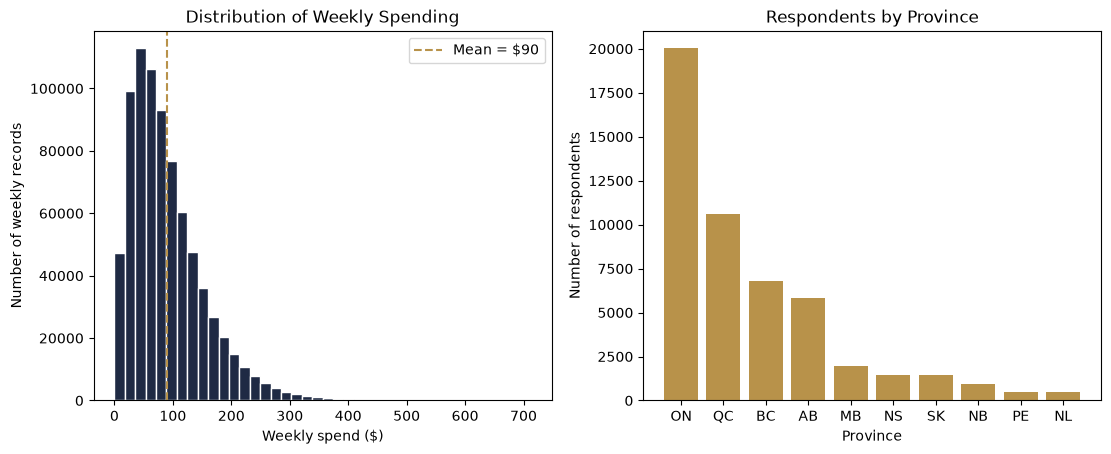

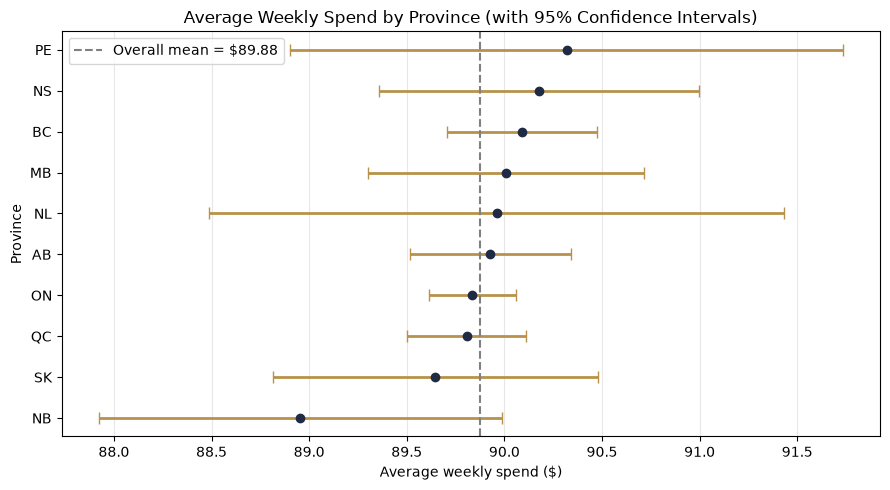

In [21]:
if "weekly_spending" not in globals():
    source_df = pd.read_csv("data/messy_survey_wide_50k.csv")
    wk_cols = [col for col in source_df.columns if col.startswith("wk")]
    weekly_spending = source_df.melt(
        id_vars=["respondent_id", "province"],
        value_vars=wk_cols,
        var_name="week",
        value_name="spend",
    ).dropna(subset=["spend"])

fig, ax = plt.subplots(1, 2, figsize=(13, 4.8))

# Plot 1: distribution of weekly spending (from the long weekly_spending table)
ax[0].hist(weekly_spending["spend"], bins=40, color="#1F2A44", edgecolor="white")
ax[0].axvline(weekly_spending["spend"].mean(), color="#B8924A", ls="--",
              label=f"Mean = ${weekly_spending['spend'].mean():.0f}")
ax[0].set_title("Distribution of Weekly Spending")
ax[0].set_xlabel("Weekly spend ($)")
ax[0].set_ylabel("Number of weekly records")
ax[0].legend()

# Plot 2: respondents by province (from the original respondent table)
counts = weekly_spending.drop_duplicates("respondent_id")["province"].value_counts()
ax[1].bar(counts.index, counts.values, color="#B8924A")
ax[1].set_title("Respondents by Province")
ax[1].set_xlabel("Province")
ax[1].set_ylabel("Number of respondents")

stats_by_prov = weekly_spending.groupby("province")["spend"].agg(["mean", "std", "count"])
stats_by_prov["ci95"] = 1.96 * stats_by_prov["std"] / np.sqrt(stats_by_prov["count"])
stats_by_prov = stats_by_prov.sort_values("mean")

overall_mean = weekly_spending["spend"].mean()

fig, ax = plt.subplots(figsize=(9, 5))
ax.errorbar(stats_by_prov["mean"], stats_by_prov.index, xerr=stats_by_prov["ci95"],
            fmt="o", color="#1F2A44", ecolor="#B8924A", elinewidth=2, capsize=4)
ax.axvline(overall_mean, color="grey", ls="--", label=f"Overall mean = ${overall_mean:.2f}")

ax.set_title("Average Weekly Spend by Province (with 95% Confidence Intervals)")
ax.set_xlabel("Average weekly spend ($)")
ax.set_ylabel("Province")
ax.legend()
ax.grid(axis="x", alpha=0.3)


plt.tight_layout()
plt.show()

### **Task 1.5 – PEW Reflection**

Answer **all** questions briefly in your own words:

1. What was the main structural problem with the original dataset?
2. What does `id_vars` mean in `melt()`?
3. What information moved from columns into rows?
4. How did the number of rows change after reshaping, and why?
5. Why is the long format easier to analyze or visualize?
6. What did your visualization reveal?

## Reflection: Week Number Stored in Headers (`wk1` … `wk26` → `week`, `spend`)

1. **Main structural problem:** 
- The week number was stored in the column names (`wk1` … `wk26`), so 26 columns held the same variable, weekly spending.

2. **`id_vars`:** 
- These are the columns that stay fixed during `melt()`. Here it is `respondent_id` (and `province`), so each spending value stays linked to its respondent.

3. **What moved from columns into rows:** 
- The week labels. `wk1`, `wk2`, … became values in a new `week` column, and the amounts went into a new `spend` column.

4. **Change in rows:** 
- The data grew from 50,000 rows to 779,314 rows. Melting 26 columns gives 1,300,000 rows (50,000 × 26), but about 40% of the cells were empty, and dropping them leaves 779,314.

5. **Why long format is easier:** 
- All spending is in one column, so one command works (`groupby("week")`, `groupby("province")`, or one histogram) instead of handling 26 separate columns.

6. **What the visualization revealed:** 
- Weekly spending is right-skewed with a mean of about $90, and it is nearly identical across provinces and weeks. There is no clear province or time effect in this synthetic data.

# **Section 2 – Billboard Dataset**

**Dataset source:** [Billboard-Hot-100 repository](https://github.com/hajimariyam/Billboard-Hot-100)

**Important:** This source contains weekly chart records in a long format (one row per song appearance in a weekly chart). The original classic Billboard file was wide, with one column per week. To practise both `pivot()` and `melt()` meaningfully, this notebook creates a compact wide table from the long data using `pivot()`, then uses `melt()` to return to long format. The original source rows are retained separately.

## 2.1. Data source and setup

Download the CSV from the direct link below and save it inside the `data` folder as `charts_top50_2001_2020.csv`. The loading cell checks both locations.

- [Download the full Billboard Top 50 CSV (2001–2020)](https://raw.githubusercontent.com/hajimariyam/Billboard-Hot-100/main/charts_top50_2001_2020.csv)
- Repository documentation says the data is separated into three CSV files by period and sorted newest to oldest, then by rank.

In [22]:
from pathlib import Path
import re
import urllib.request
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


billboard_raw = pd.read_csv("./data/billboard.csv", encoding="unicode_escape")
print("Raw shape:", billboard_raw.shape)

Raw shape: (52150, 7)


## 2.2. Inspect and standardize the schema

Inspect the actual column names before writing cleaning logic. The next cell standardizes column labels for easier coding without changing the meaning of the fields.

In [23]:
print("Columns:", billboard_raw.columns.tolist())
display(billboard_raw.head())
display(billboard_raw.info())

Columns: ['date', 'rank', 'song', 'artist', 'last-week', 'peak-rank', 'weeks-on-board']


,date,rank,song,artist,last-week,peak-rank,weeks-on-board
0,12/26/2020,1,Willow,Taylor Swift,NaN,1,1
1,12/26/2020,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42
2,12/26/2020,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37
3,12/26/2020,4,Jingle Bell Rock,Bobby Helms,5.0,3,34
4,12/26/2020,5,Mood,24kGoldn Featuring iann dior,2.0,1,19


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52150 entries, 0 to 52149
Data columns (total 7 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   date            52150 non-null  object 
 1   rank            52150 non-null  int64  
 2   song            52150 non-null  object 
 3   artist          52150 non-null  object 
 4   last-week       50501 non-null  float64
 5   peak-rank       52150 non-null  int64  
 6   weeks-on-board  52150 non-null  int64  
dtypes: float64(1), int64(3), object(3)
memory usage: 2.8+ MB


None

In [24]:
billboard = billboard_raw.copy()

def standardize_column_name(column):
    column = str(column).strip().lower()
    column = re.sub(r"[^a-z0-9]+", "_", column)
    return column.strip("_")

billboard.columns = [standardize_column_name(c) for c in billboard.columns]

print("Standardized columns:", billboard.columns.tolist())
display(billboard.head())

Standardized columns: ['date', 'rank', 'song', 'artist', 'last_week', 'peak_rank', 'weeks_on_board']


,date,rank,song,artist,last_week,peak_rank,weeks_on_board
0,12/26/2020,1,Willow,Taylor Swift,NaN,1,1
1,12/26/2020,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42
2,12/26/2020,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37
3,12/26/2020,4,Jingle Bell Rock,Bobby Helms,5.0,3,34
4,12/26/2020,5,Mood,24kGoldn Featuring iann dior,2.0,1,19


## 2.3. Initial EDA

Review row counts, column types, numeric summaries, and missing values before making any cleaning decisions.

In [25]:
print(f"Rows: {len(billboard):,}")
print(f"Columns: {billboard.shape[1]:,}")
display(billboard.dtypes.to_frame("dtype"))
display(billboard.describe(include="all").T)
missing_summary = (
    billboard.isna().sum()
    .rename("missing_count")
    .to_frame()
    .assign(missing_percent=lambda x: (x["missing_count"] / len(billboard) * 100).round(2))
    .sort_values("missing_count", ascending=False)
)
display(missing_summary)

Rows: 52,150
Columns: 7


,dtype
date,object
rank,int64
song,object
artist,object
last_week,float64
peak_rank,int64
weeks_on_board,int64


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
date,52150,1043,12/26/2020,50,NaN,NaN,NaN,NaN,NaN,NaN,NaN
rank,52150.0,NaN,NaN,NaN,25.5,14.431008,1.0,13.0,25.5,38.0,50.0
song,52150,3915,Rockstar,105,NaN,NaN,NaN,NaN,NaN,NaN,NaN
artist,52150,2124,Taylor Swift,701,NaN,NaN,NaN,NaN,NaN,NaN,NaN
last_week,50501.0,NaN,NaN,NaN,25.941447,15.949158,1.0,13.0,25.0,38.0,100.0
peak_rank,52150.0,NaN,NaN,NaN,16.941841,14.282851,1.0,4.0,13.0,28.0,50.0
weeks_on_board,52150.0,NaN,NaN,NaN,15.84581,10.53846,1.0,8.0,14.0,21.0,87.0


,missing_count,missing_percent
last_week,1649,3.16
rank,0,0.00
date,0,0.00
song,0,0.00
artist,0,0.00
peak_rank,0,0.00
weeks_on_board,0,0.00


### Findings and Reflection

The Billboard dataset contains 52,150 rows and 7 columns. The data types and descriptive statistics provide an overview of the available variables and their distributions.

The missing-value analysis shows that the `last_week` column contains 1,649 missing values, representing 3.16% of the records. The other six columns have no missing values. Missing values in `last_week` may indicate that a song entered the chart without a previous-week ranking, so they should be investigated before deciding how to handle them.

This initial EDA helps identify potential data-quality issues and guides the next steps in data cleaning, string manipulation, and reshaping. The original dataset is already in long format, so a sample can be used to demonstrate `pivot()` and `melt()` for the assignment's tidying requirement.

## 2.4. Identify the data structure and field meanings

This CSV represents weekly chart appearances rather than one row per unique song. Check whether date, current rank, song, and artist fields are present. The schema guard below avoids silently applying later code to an unexpected file.

In [26]:
required_any = {
    "date": ["date", "chart_date", "chart_week"],
    "song": ["song", "track", "title"],
    "artist": ["artist", "artist_name"],
    "current_rank": ["this_week", "thisweek", "rank", "current_rank", "position"],
    "previous_rank": ["last_week", "lastweek", "previous_rank"],
    "peak_rank": ["peak_position", "peak", "peak_rank"],
    "weeks_on_chart": ["weeks_on_chart", "weeks", "weeks_on_chart"],
    
    #"weeks_on_chart": ["weeks_on_chart", "weeks_on_board", "weeks"]
}

resolved = {}
for field, options in required_any.items():
    match = next((name for name in options if name in billboard.columns), None)
    resolved[field] = match

display(pd.DataFrame({"logical_field": list(resolved), "matched_column": list(resolved.values())}))

for field in ["song", "artist", "current_rank"]:
    if resolved[field] is None:
        raise ValueError(
            f"Could not identify the {field!r} column. Check the printed schema "
            "and update the mapping options for this source file."
        )

,logical_field,matched_column
0,date,date
1,song,song
2,artist,artist
3,current_rank,rank
4,previous_rank,last_week
5,peak_rank,peak_rank
6,weeks_on_chart,None


### Findings and Reflection

The schema validation confirms that the dataset contains the expected fields for date, song, artist, current rank, previous rank, and peak rank. The `weeks_on_chart` field was not matched because the dataset uses the column name `weeks_on-board` rather than the alternatives defined in the code.

The matched columns are `date`, `song`, `artist`, `rank`, `last_week`, and `peak_rank`. These fields provide information about when a song appeared on the chart, its current and previous rankings, and its highest ranking.

This check is useful because it identifies differences between the expected field names and the actual dataset schema before further processing. The column mapping should be updated to recognize `weeks_on-board` so that all seven fields can be identified correctly.

## 2.5. Data-quality checks

Check exact duplicate rows, missing values in key identifiers, and unexpected rank values. A valid chart position is typically between 1 and 100 for the Billboard Hot 100, while this source file focuses on Top 50 entries.

In [27]:
duplicate_rows = int(billboard.duplicated().sum())
print("Exact duplicate rows:", duplicate_rows)

key_cols = [resolved["song"], resolved["artist"]]
if resolved["date"]:
    key_cols.append(resolved["date"])

print("Missing key-field values:")
display(billboard[key_cols].isna().sum().to_frame("missing_count"))

rank_col = resolved["current_rank"]
billboard[rank_col] = pd.to_numeric(billboard[rank_col], errors="coerce")
print("Current-rank values outside 1–100:")
display(billboard.loc[~billboard[rank_col].between(1, 100), [rank_col]].head(10))

Exact duplicate rows: 0
Missing key-field values:


,missing_count
song,0
artist,0
date,0


Current-rank values outside 1–100:


,rank


### Findings and reflection

The data-quality checks found 0 exact duplicate rows in the Billboard dataset. The key fields song, artist, and date each contain 0 missing values, indicating that these essential fields are complete for identifying chart appearances.

The current-rank validation also found no values outside the range of 1–100. Therefore, all current rankings pass this validation check.

These results suggest that the dataset has no exact duplicate rows or missing values in its key identifier fields, and its current rankings fall within the expected range. However, the earlier EDA identified 1,649 missing values in the last_week column (3.16% of records). These should be investigated because a missing previous-week rank may occur when a song first enters the chart.

Overall, the checks provide a useful baseline for data quality before proceeding with further cleaning, string manipulation, feature engineering, and reshaping using melt().

## 2.6. Cleaning and validation

The cleaning process keeps the raw DataFrame intact, trims text, converts dates and numeric columns when they can be identified, and removes only exact duplicate records. Missing previous-week rank values are not automatically imputed because a blank can mean a song was not on the chart the previous week.

In [28]:
clean = billboard.copy()

# Trim leading/trailing whitespace from text fields.
text_cols = clean.select_dtypes(include=["object", "string"]).columns
for col in text_cols:
    clean[col] = clean[col].astype("string").str.strip()

# Parse the date column if one was identified.
date_col = resolved["date"]
if date_col:
    clean[date_col] = pd.to_datetime(clean[date_col], errors="coerce")

# Convert ranking/count columns when available.
numeric_fields = ["current_rank", "previous_rank", "peak_rank", "weeks_on_chart"]
for field in numeric_fields:
    col = resolved.get(field)
    if col and col in clean.columns:
        clean[col] = pd.to_numeric(clean[col], errors="coerce")

before = len(clean)
clean = clean.drop_duplicates().copy()
print(f"Removed {before - len(clean):,} exact duplicate rows.")
print("Clean shape:", clean.shape)
display(clean.head())

Removed 0 exact duplicate rows.
Clean shape: (52150, 7)


,date,rank,song,artist,last_week,peak_rank,weeks_on_board
0,2020-12-26,1,Willow,Taylor Swift,NaN,1,1
1,2020-12-26,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42
2,2020-12-26,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37
3,2020-12-26,4,Jingle Bell Rock,Bobby Helms,5.0,3,34
4,2020-12-26,5,Mood,24kGoldn Featuring iann dior,2.0,1,19


In [29]:
# Validate cleaning: report missingness and data types again.
display(clean.isna().sum().to_frame("missing_after_cleaning"))
display(clean.dtypes.to_frame("dtype_after_cleaning"))

,missing_after_cleaning
date,0
rank,0
song,0
artist,0
last_week,1649
peak_rank,0
weeks_on_board,0


,dtype_after_cleaning
date,datetime64[ns]
rank,int64
song,string[python]
artist,string[python]
last_week,float64
peak_rank,int64
weeks_on_board,int64


### Findings and Reflection

The cleaning and validation process removed **0 exact duplicate rows**, so the dataset retained all **52,150 rows and 7 columns**. Leading and trailing whitespace was trimmed from text fields, the `date` column was converted to a datetime data type, and the ranking-related columns were converted to numeric types where applicable.

After cleaning, the missing-value check showed that the `last_week` column still contains **1,649 missing values**, while all other columns have no missing values. These missing values were retained rather than automatically imputed because a missing previous-week ranking may indicate that a song was not on the chart in the preceding week.

The updated data types confirm that `date` is stored as `datetime64`, `rank` and `peak_rank` are integers, and `last_week` is a floating-point column because it contains missing values. The `song` and `artist` columns are stored as strings.

Overall, the cleaning process improved data consistency while preserving meaningful missing values and the original raw dataset. The cleaned DataFrame is now ready for further exploratory analysis, feature engineering, and reshaping with `melt()`.

## 2.7. Missing-value analysis

Compare missingness in the previous-week rank with missingness in the current rank. A missing previous-week value can be meaningful for a new chart entry; a missing current rank is more problematic for a row that purports to be a chart appearance.


In [30]:
for field in ["current_rank", "previous_rank", "peak_rank", "weeks_on_chart"]:
    col = resolved.get(field)
    if col and col in clean.columns:
        print(f"{field} ({col}): {clean[col].isna().sum():,} missing values")

previous_col = resolved.get("previous_rank")
if previous_col:
    print("Rows with missing previous-week rank:", int(clean[previous_col].isna().sum()))

current_rank (rank): 0 missing values
previous_rank (last_week): 1,649 missing values
peak_rank (peak_rank): 0 missing values
Rows with missing previous-week rank: 1649


## 2.8. Feature engineering and string manipulation

Create useful date features and a rank-change feature. Positive `rank_improvement` means the song moved to a smaller (better) rank number compared with the previous week. If the previous rank is missing, the change remains missing rather than being guessed.

In [31]:
features = clean.copy()

if date_col:
    features["chart_year"] = features[date_col].dt.year
    features["chart_month"] = features[date_col].dt.month
    features["chart_day_name"] = features[date_col].dt.day_name()

current_col = resolved["current_rank"]
previous_col = resolved.get("previous_rank")
if previous_col:
    # Positive values mean improvement: previous rank minus current rank.
    features["rank_improvement"] = features[previous_col] - features[current_col]

song_col = resolved["song"]
artist_col = resolved["artist"]
features["song_clean"] = features[song_col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()
features["artist_clean"] = features[artist_col].astype("string").str.replace(r"\s+", " ", regex=True).str.strip()

display(features.head())

,date,rank,song,artist,last_week,peak_rank,weeks_on_board,chart_year,chart_month,chart_day_name,rank_improvement,song_clean,artist_clean
0,2020-12-26,1,Willow,Taylor Swift,NaN,1,1,2020,12,Saturday,NaN,Willow,Taylor Swift
1,2020-12-26,2,All I Want For Christmas Is You,Mariah Carey,1.0,1,42,2020,12,Saturday,-1.0,All I Want For Christmas Is You,Mariah Carey
2,2020-12-26,3,Rockin' Around The Christmas Tree,Brenda Lee,3.0,2,37,2020,12,Saturday,0.0,Rockin' Around The Christmas Tree,Brenda Lee
3,2020-12-26,4,Jingle Bell Rock,Bobby Helms,5.0,3,34,2020,12,Saturday,1.0,Jingle Bell Rock,Bobby Helms
4,2020-12-26,5,Mood,24kGoldn Featuring iann dior,2.0,1,19,2020,12,Saturday,-3.0,Mood,24kGoldn Featuring iann dior


## 2.9. EDA: chart rankings and potential outliers

Use plots and summary statistics to explore the current chart rank and rank changes. Because chart rank is bounded and its meaning is ordinal, extreme ranks are not automatically data errors. Investigate unusual values instead of deleting them by default.

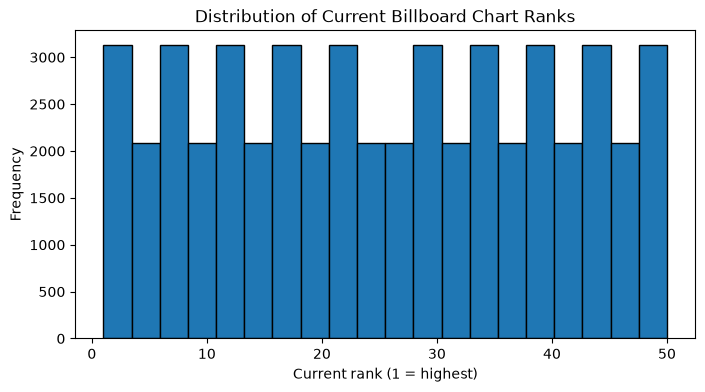

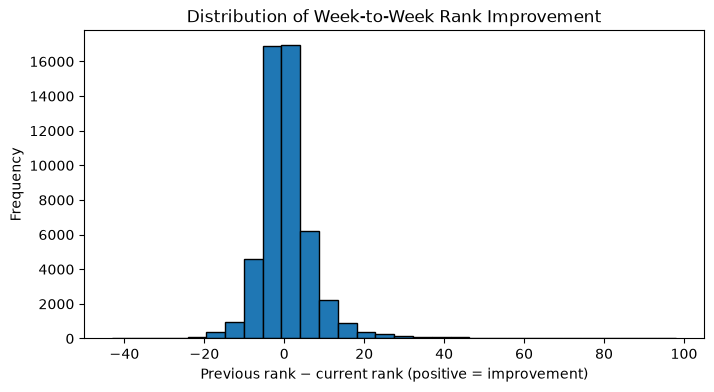

,count,mean,std,min,25%,50%,75%,max
rank,52150.0,25.50000,14.431008,1.0,13.0,25.5,38.0,50.0
rank_improvement,50501.0,0.54494,7.633199,-43.0,-3.0,0.0,3.0,98.0


In [32]:
plt.figure(figsize=(8, 4))
features[current_col].dropna().plot(kind="hist", bins=20, edgecolor="black")
plt.title("Distribution of Current Billboard Chart Ranks")
plt.xlabel("Current rank (1 = highest)")
plt.ylabel("Frequency")
plt.show()

if "rank_improvement" in features.columns:
    plt.figure(figsize=(8, 4))
    features["rank_improvement"].dropna().plot(kind="hist", bins=30, edgecolor="black")
    plt.title("Distribution of Week-to-Week Rank Improvement")
    plt.xlabel("Previous rank − current rank (positive = improvement)")
    plt.ylabel("Frequency")
    plt.show()

display(features[[current_col] + (["rank_improvement"] if "rank_improvement" in features.columns else [])].describe().T)

### Findings and Reflection

The histogram of current Billboard chart rankings shows an approximately uniform distribution across ranks 1–50. This pattern is expected because the dataset records Top 50 chart entries for each chart date, with each rank represented regularly.

The distribution of `rank_improvement` is concentrated around zero, indicating that many songs experience relatively small changes in their rankings from one week to the next. Positive values represent improvements in ranking, while negative values indicate declines. The histogram also shows some larger changes, suggesting that certain songs move substantially up or down the chart between weeks.

The summary statistics show that `rank_improvement` has 50,501 non-missing observations, compared with 52,150 current-rank observations. This difference is consistent with the missing previous-week rankings identified earlier. These missing values were excluded from the rank-improvement histogram rather than being estimated.

Overall, the visualizations help describe chart-position patterns and week-to-week movements. Extreme ranking changes should be investigated in context rather than automatically treated as data errors or removed from the dataset.

## 2.10. Practise `pivot()` and `melt()` using a song-week table

The source CSV is already long format. To demonstrate both reshaping operations, create a stable song identifier, pivot a small selection of songs into one column per chart date, and melt that table back to long format. This is an instructional transformation; the original `features` table remains unchanged.

If multiple rows exist for the same song and date, the pivot validation below will detect the issue. The code uses a composite song/artist key because titles alone are not guaranteed to be unique.

In [33]:
# Demonstrate pivot() and melt() using a manageable sample of song/artist pairs.
# The complete source is already long format (one row per chart appearance).
if date_col is None:
    raise ValueError("A date/chart-week column is required for the pivot/melt demonstration.")

wide_source = features.copy()
wide_source["song_artist_key"] = (
    wide_source[song_col].astype("string").fillna("<missing song>")
    + " — "
    + wide_source[artist_col].astype("string").fillna("<missing artist>")
)

sample_keys = wide_source["song_artist_key"].drop_duplicates().head(20)
sample_long = wide_source[wide_source["song_artist_key"].isin(sample_keys)].copy()

# A pivot requires one value per song/artist/date. Report and resolve collisions for this demonstration.
duplicate_song_dates = int(sample_long.duplicated(["song_artist_key", date_col]).sum())
print("Duplicate song/artist/date combinations before resolving:", duplicate_song_dates)
if duplicate_song_dates:
    sample_long = sample_long.drop_duplicates(["song_artist_key", date_col], keep="first")

wide_demo = sample_long.pivot(
    index="song_artist_key",
    columns=date_col,
    values=current_col
)
display(wide_demo.head())
print("Wide demonstration shape:", wide_demo.shape)


Duplicate song/artist/date combinations before resolving: 0


date,2012-12-22,2012-12-29,2013-01-05,2013-12-21,2013-12-28,2014-01-04,2014-12-20,2014-12-27,2015-01-03,2015-12-19,2015-12-26,2016-01-02,2016-01-09,2016-12-17,2016-12-24,2016-12-31,2017-01-07,2017-01-14,2017-12-16,2017-12-23,2017-12-30,2018-01-06,2018-12-01,2018-12-08,2018-12-15,2018-12-22,2018-12-29,2019-01-05,2019-11-23,2019-11-30,2019-12-07,2019-12-14,2019-12-21,2019-12-28,2020-01-04,2020-01-18,2020-01-25,2020-02-01,2020-02-08,2020-02-15,2020-02-22,2020-02-29,2020-03-07,2020-03-14,2020-03-21,2020-03-28,2020-04-04,2020-04-11,2020-04-18,2020-04-25,2020-05-02,2020-05-09,2020-05-16,2020-05-23,2020-05-30,2020-06-06,2020-06-13,2020-06-20,2020-06-27,2020-07-04,2020-07-11,2020-07-18,2020-07-25,2020-08-01,2020-08-08,2020-08-15,2020-08-22,2020-08-29,2020-09-05,2020-09-12,2020-09-19,2020-09-26,2020-10-03,2020-10-10,2020-10-17,2020-10-24,2020-10-31,2020-11-07,2020-11-14,2020-11-21,2020-11-28,2020-12-05,2020-12-12,2020-12-19,2020-12-26
song_artist_key,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
A Holly Jolly Christmas — Burl Ives,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,46.0,NaN,NaN,47.0,41.0,46.0,NaN,26.0,22.0,21.0,12.0,10.0,NaN,NaN,48.0,18.0,10.0,6.0,4.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,24.0,14.0,6.0
All I Want For Christmas Is You — Mariah Carey,29.0,25.0,21.0,26.0,27.0,26.0,50.0,40.0,35.0,26.0,22.0,18.0,11.0,23.0,17.0,20.0,16.0,35.0,21.0,11.0,9.0,13.0,29.0,14.0,7.0,6.0,7.0,3.0,39.0,31.0,18.0,3.0,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,29.0,14.0,2.0,1.0,2.0
Blinding Lights — The Weeknd,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11.0,NaN,NaN,NaN,39.0,32.0,21.0,18.0,15.0,12.0,10.0,8.0,7.0,4.0,2.0,1.0,1.0,2.0,1.0,1.0,2.0,3.0,4.0,3.0,4.0,3.0,3.0,5.0,3.0,3.0,2.0,4.0,4.0,5.0,4.0,3.0,4.0,5.0,5.0,5.0,5.0,7.0,6.0,6.0,4.0,4.0,5.0,4.0,5.0,7.0,9.0,11.0,7.0,18.0
Dynamite — BTS,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,1.0,2.0,2.0,1.0,2.0,2.0,5.0,7.0,12.0,16.0,17.0,14.0,3.0,10.0,24.0,9.0
Feliz Navidad — Jose Feliciano,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,42.0,34.0,29.0,NaN,NaN,NaN,39.0,34.0,23.0,12.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,45.0,16.0,10.0,10.0


Wide demonstration shape: (20, 85)


In [34]:
# melt() converts the date columns back into rows.
melted_demo = (
    wide_demo.reset_index()
    .melt(
        id_vars="song_artist_key",
        var_name="chart_date",
        value_name="current_rank"
    )
    .dropna(subset=["current_rank"])
    .reset_index(drop=True)
)

# Split the display key back into song and artist for a more useful tidy result.
key_parts = melted_demo["song_artist_key"].str.split(" — ", n=1, expand=True)
melted_demo["song"] = key_parts[0]
melted_demo["artist"] = key_parts[1]
melted_demo = melted_demo[["song", "artist", "chart_date", "current_rank"]]

display(melted_demo.head())
print("Melted demonstration shape:", melted_demo.shape)
print("Each remaining row represents a song/artist on one chart date.")

,song,artist,chart_date,current_rank
0,All I Want For Christmas Is You,Mariah Carey,2012-12-22 00:00:00,29.0
1,All I Want For Christmas Is You,Mariah Carey,2012-12-29 00:00:00,25.0
2,All I Want For Christmas Is You,Mariah Carey,2013-01-05 00:00:00,21.0
3,All I Want For Christmas Is You,Mariah Carey,2013-12-21 00:00:00,26.0
4,All I Want For Christmas Is You,Mariah Carey,2013-12-28 00:00:00,27.0


Melted demonstration shape: (394, 4)
Each remaining row represents a song/artist on one chart date.


### Findings and Reflection

The reshaping exercise demonstrates how `pivot()` and `melt()` transform the Billboard dataset between wide and long formats. The source dataset is already in long format, with each row representing a song's chart appearance on a particular date.

Using `pivot()`, a sample of 20 song–artist combinations was transformed into a wide table, with each chart date represented as a separate column and the current rank stored as the value. The validation found **0 duplicate song–artist–date combinations** in the selected sample, so no duplicate records needed to be removed before pivoting.

The `melt()` function then converted the wide table back into long format, producing columns for `song`, `artist`, `chart_date`, and `current_rank`. Rows without a recorded rank were excluded from the reshaped demonstration.

This exercise illustrates how `pivot()` and `melt()` support data reshaping and tidying. The transformation was performed on a sample for demonstration purposes, leaving the original `features` DataFrame unchanged.

## 2.11. Aggregation: weekly chart summary

Summarize the number of chart entries and average rank by chart date. These statistics describe the chart records, not the entire music market.

In [35]:
weekly_summary = (
    features.groupby(date_col, dropna=False)
    .agg(
        chart_entries=(current_col, "count"),
        mean_rank=(current_col, "mean"),
        median_rank=(current_col, "median"),
        best_rank=(current_col, "min"),
    )
    .reset_index()
    .sort_values(date_col)
)
display(weekly_summary.head())
display(weekly_summary.tail())


,date,chart_entries,mean_rank,median_rank,best_rank
0,2001-01-06,50,25.5,25.5,1
1,2001-01-13,50,25.5,25.5,1
2,2001-01-20,50,25.5,25.5,1
3,2001-01-27,50,25.5,25.5,1
4,2001-02-03,50,25.5,25.5,1


,date,chart_entries,mean_rank,median_rank,best_rank
1038,2020-11-28,50,25.5,25.5,1
1039,2020-12-05,50,25.5,25.5,1
1040,2020-12-12,50,25.5,25.5,1
1041,2020-12-19,50,25.5,25.5,1
1042,2020-12-26,50,25.5,25.5,1


### Findings and Reflection

The weekly chart summary aggregates Billboard records by chart date to examine the number of chart entries and the distribution of rankings over time. The summary calculates four measures: chart_entries, mean_rank, median_rank, and best_rank.

The number of chart entries indicates how many records are available for each date, while the mean and median ranks describe the typical ranking positions. The best rank represents the smallest rank number recorded for that date, where rank 1 is the highest position.

Sorting the summary by date makes it easier to examine changes across chart weeks. These statistics provide an overview of chart activity and ranking patterns, but they describe the records in this dataset rather than the entire music market.

## 2.12. Conclusion

This analysis explored the Billboard chart dataset containing 52,150 records and seven columns. The initial inspection and data-quality checks identified missing previous-week rankings while confirming that there were no exact duplicate rows, no missing values in the key identifier fields, and no current-rank values outside the range of 1–100.

The data-cleaning process standardized text fields, converted dates and numeric columns to appropriate data types, and retained meaningful missing values rather than replacing them with assumptions. Feature engineering added date-based variables and a `rank_improvement` measure to help examine changes in chart positions over time.

Exploratory data analysis was used to examine current chart rankings and week-to-week rank changes. The weekly aggregation summarized chart entries, mean rank, median rank, and best rank by chart date. The `pivot()` and `melt()` exercises also demonstrated how data can be reshaped between wide and long formats to support different analytical needs.

Overall, this section provided practical experience with data inspection, cleaning, validation, string manipulation, feature engineering, visualization, aggregation, and data reshaping using Pandas. These techniques help prepare structured data for reliable analysis while preserving the meaning of the original records.

One limitation is that the reshaping demonstration used a sample of song–artist combinations rather than the entire dataset. Future work could explore longer-term chart trends, compare ranking movements across artists, and investigate songs with unusually large changes in chart position.

# **Section 3 – Data Cleaning (Cars Dataset)**

## **Learning Topic: Data Cleaning and Missing Data Handling**

Data cleaning includes identifying invalid, irrelevant, duplicated, inconsistent, or missing data and deciding how to treat it.

In this section you will work with the Auto MPG / Cars dataset and compare several missing-data strategies.

### Required functions and concepts

- `isnull()` / `isna()`
- `notnull()` / `notna()`
- `dropna()`
- `fillna()`
- `mean()`
- `median()`
- `mode()`
- duplicate detection/removal
- numeric conversion
- `SimpleImputer`

## **Getting the Cars (Auto MPG) Dataset from the Internet**

Use the **Auto MPG** dataset from the UCI Machine Learning Repository. UCI describes it as a regression dataset concerning city-cycle fuel consumption. It contains variables such as MPG, cylinders, displacement, horsepower, weight, acceleration, model year, origin, and car name.

### Recommended source

Official UCI dataset page:

`https://archive.ics.uci.edu/dataset/9/auto+mpg`

The UCI page provides the dataset files and documentation. The raw file is named **`auto-mpg.data`** rather than `cars.csv`.

### Recommended student workflow

1. Open the UCI page above.
2. Download the Auto MPG dataset.
3. Extract the downloaded archive if necessary.
4. Locate **`auto-mpg.data`**.
5. Place it in your project's `data/` folder.
6. Keep the original raw file rather than editing it manually.

Your project can look like:

```text
project/
├── week5Lab.ipynb
└── data/
    └── auto-mpg.data
```

### Loading the UCI raw file with Pandas

Because this file is whitespace-delimited rather than a normal comma-separated CSV, supply the column names when reading it:

```python
column_names = [
    "MPG", "Cylinders", "Displacement", "Horsepower",
    "Weight", "Acceleration", "ModelYear", "Origin", "CarName"
]

cars = pd.read_csv(
    "./data/auto-mpg.data",
    sep=r"\s+",
    names=column_names,
    na_values="?",
    quotechar='"'
)
```

The `na_values="?"` argument is important because the UCI dataset uses `?` for missing horsepower values.

### Optional: create a local CSV working copy

After correctly loading the original UCI file, you may save a CSV copy:

```python
cars.to_csv("./data/cars.csv", index=False)
```

You can then reload it later with:

```python
cars = pd.read_csv("./data/cars.csv")
```

### Verify before continuing

Check:

```python
cars.shape
cars.head()
cars.dtypes
cars.isnull().sum()
```

The UCI version contains **398 instances**, and `Horsepower` contains missing values. If your results are substantially different, verify your download and loading code.

> **Good practice:** Preserve the original raw file. If you create `cars.csv`, treat it as a derived working copy rather than silently replacing the source data.

### **Task 3.1 – Load and Inspect the Cars Dataset**

1. Load the Cars dataset from your data folder.
2. Inspect shape, columns, data types, and sample rows.
3. Determine whether any row contains metadata or data-type labels rather than an actual car observation.
4. Remove irrelevant rows **only if justified by inspection**.

#### Load and Inspect the Dataset

**Objective:** Load the CarDekho dataset and understand its structure before performing data cleaning.

Before cleaning a dataset, it is important to understand what information is available, how the columns are organized, and whether any columns are unnecessary.

**Steps performed:**

- Load the CSV file using Pandas.
- Check the dataset shape to identify the number of rows and columns.
- Display the first and last five records.
- Examine column names and data types.
- Identify unnecessary columns, such as an exported row index.
- Create a copy of the original dataset for future comparison.

This initial inspection helps identify potential data-quality issues and prepares the dataset for further cleaning.

In [36]:

import pandas as pd
import numpy as np

# Load the CarDekho dataset
cars = pd.read_csv("data/cardekho_dataset.csv")

# Preserve original dataset
cars_original = cars.copy()

# Check dataset shape
print("Dataset Shape:", cars.shape)

# Display column names
print("\nColumn Names:")
print(cars.columns.tolist())

# Check data types
print("\nData Types:")
print(cars.dtypes)

# Display sample records
print("\nFirst 5 Rows:")
display(cars.head())

print("\nLast 5 Rows:")
display(cars.tail())

# Identify exported index columns
index_columns = [
    col for col in cars.columns
    if col.startswith("Unnamed:")
]

print("\nUnnecessary Index Columns:", index_columns)

# Remove the exported index column
cars = cars.drop(columns=index_columns)

print("\nShape After Removing Index Column:", cars.shape)


Dataset Shape: (15411, 14)

Column Names:
['Unnamed: 0', 'car_name', 'brand', 'model', 'vehicle_age', 'km_driven', 'seller_type', 'fuel_type', 'transmission_type', 'mileage', 'engine', 'max_power', 'seats', 'selling_price']

Data Types:
Unnamed: 0             int64
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

First 5 Rows:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
0,0,Maruti Alto,Maruti,Alto,9,120000,Individual,Petrol,Manual,19.70,796,46.30,5,120000
1,1,Hyundai Grand,Hyundai,Grand,5,20000,Individual,Petrol,Manual,18.90,1197,82.00,5,550000
2,2,Hyundai i20,Hyundai,i20,11,60000,Individual,Petrol,Manual,17.00,1197,80.00,5,215000
3,3,Maruti Alto,Maruti,Alto,9,37000,Individual,Petrol,Manual,20.92,998,67.10,5,226000
4,4,Ford Ecosport,Ford,Ecosport,6,30000,Dealer,Diesel,Manual,22.77,1498,98.59,5,570000



Last 5 Rows:


,Unnamed: 0,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
15406,19537,Hyundai i10,Hyundai,i10,9,10723,Dealer,Petrol,Manual,19.81,1086,68.05,5,250000
15407,19540,Maruti Ertiga,Maruti,Ertiga,2,18000,Dealer,Petrol,Manual,17.50,1373,91.10,7,925000
15408,19541,Skoda Rapid,Skoda,Rapid,6,67000,Dealer,Diesel,Manual,21.14,1498,103.52,5,425000
15409,19542,Mahindra XUV500,Mahindra,XUV500,5,3800000,Dealer,Diesel,Manual,16.00,2179,140.00,7,1225000
15410,19543,Honda City,Honda,City,2,13000,Dealer,Petrol,Automatic,18.00,1497,117.60,5,1200000



Unnecessary Index Columns: ['Unnamed: 0']

Shape After Removing Index Column: (15411, 13)


#### Observation – Task 3.1

The CarDekho dataset initially contained **15,411 rows and 14 columns**. It includes both numerical and categorical features, such as mileage, engine power, fuel type, and selling price.

I removed the unnecessary `Unnamed: 0` index column, leaving **15,411 rows and 13 columns** for further analysis.

### **Task 3.2 – Assess Missing and Invalid Values**

1. Count missing values in every column.
2. Calculate the percentage of missing values.
3. Use `notnull()` or `notna()` at least once to confirm valid observations.
4. Check for values that should be numeric but are stored as text.
5. Convert columns to appropriate data types where needed.

#### Assess Missing and Invalid Values

**Objective:** Identify missing values, verify data types, and check for invalid numerical values.

Missing values and invalid records can affect statistical analysis and machine learning models. Therefore, it is important to check the dataset before applying any imputation.

**Steps performed:**
1. Count missing values using `isnull()`.
2. Calculate the missing-value percentage.
3. Count valid observations using `notnull()`.
4. Check data types.
5. Identify potentially invalid numerical values such as negative prices or mileage.

No records will be removed in this task. The goal is to assess data quality.

In [37]:

# Count missing values in every column
missing_count = cars.isnull().sum()

# Calculate missing percentages
missing_percentage = (
    cars.isnull().mean() * 100
).round(2)

missing_summary = pd.DataFrame({
    "Missing Count": missing_count,
    "Missing Percentage (%)": missing_percentage
})

display(missing_summary)

# Count valid selling prices
print("Valid Selling Prices:",
      cars["selling_price"].notnull().sum())

# Check data types
print("\nData Types:")
print(cars.dtypes)

# Check invalid numeric values
invalid_checks = {
    "Negative Vehicle Age": (cars["vehicle_age"] < 0).sum(),
    "Negative KM Driven": (cars["km_driven"] < 0).sum(),
    "Non-positive Selling Price": (cars["selling_price"] <= 0).sum(),
    "Negative Mileage": (cars["mileage"] < 0).sum(),
    "Non-positive Engine Capacity": (cars["engine"] <= 0).sum(),
    "Non-positive Maximum Power": (cars["max_power"] <= 0).sum()
}

print("\nPotential Invalid Values:")
display(pd.DataFrame(
    invalid_checks.items(),
    columns=["Check", "Count"]
))

print("\nTotal Missing Values:",
      cars.isnull().sum().sum())


,Missing Count,Missing Percentage (%)
car_name,0,0.0
brand,0,0.0
model,0,0.0
vehicle_age,0,0.0
km_driven,0,0.0
seller_type,0,0.0
fuel_type,0,0.0
transmission_type,0,0.0
mileage,0,0.0
engine,0,0.0


Valid Selling Prices: 15411

Data Types:
car_name              object
brand                 object
model                 object
vehicle_age            int64
km_driven              int64
seller_type           object
fuel_type             object
transmission_type     object
mileage              float64
engine                 int64
max_power            float64
seats                  int64
selling_price          int64
dtype: object

Potential Invalid Values:


,Check,Count
0,Negative Vehicle Age,0
1,Negative KM Driven,0
2,Non-positive Selling Price,0
3,Negative Mileage,0
4,Non-positive Engine Capacity,0
5,Non-positive Maximum Power,0



Total Missing Values: 0


#### Observation – Task 3.2

The dataset contains **no missing values** across all 13 columns. All 15,411 selling-price records are available.

The basic validity checks also found no negative vehicle ages, kilometers driven, or mileage values, and no non-positive selling prices, engine capacities, or maximum power values.

### **Task 3.3 – Check Duplicates**

Identify duplicate records.

- Report the number of duplicates.
- Remove duplicates if present.
- If there are none, state that clearly.

#### Check and Remove Duplicates

**Objective:** Identify duplicate car records and remove them if necessary.

Duplicate records can affect calculations by counting the same information multiple times.

**Steps performed:**
1. Check the dataset shape.
2. Count duplicate rows using `duplicated()`.
3. Display repeated records.
4. Remove exact duplicates using `drop_duplicates()`.
5. Compare the dataset size before and after cleaning.

The exported index was removed in Task 3.1 because a unique index can hide duplicate rows. Cars with similar specifications are not automatically duplicates of the same physical vehicle.

In [38]:

# Dataset before duplicate removal
print("Shape Before:", cars.shape)

# Check for duplicate records
duplicate_count = cars.duplicated().sum()

print("Duplicate Records:", duplicate_count)

# Display duplicate records if present
if duplicate_count > 0:
    display(cars[cars.duplicated()])
else:
    print("No exact duplicate records found.")

# Remove exact duplicates
cars = cars.drop_duplicates().copy()

# Check final shape
print("\nShape After:", cars.shape)

print("Rows Removed:", duplicate_count)


Shape Before: (15411, 13)
Duplicate Records: 167


,car_name,brand,model,vehicle_age,km_driven,seller_type,fuel_type,transmission_type,mileage,engine,max_power,seats,selling_price
197,Honda City,Honda,City,8,70000,Individual,Petrol,Manual,16.80,1497,116.30,5,545000
360,Maruti Baleno,Maruti,Baleno,2,5000,Individual,Petrol,Automatic,21.40,1197,83.10,5,686000
1353,Maruti Swift Dzire,Maruti,Swift Dzire,4,50000,Individual,Diesel,Manual,28.40,1248,74.02,5,680000
1429,Maruti Wagon R,Maruti,Wagon R,13,100000,Individual,Petrol,Manual,18.90,1061,67.00,5,150000
1485,Hyundai i20,Hyundai,i20,3,50000,Individual,Petrol,Manual,18.60,1197,81.83,5,625000
...,...,...,...,...,...,...,...,...,...,...,...,...,...
15229,Maruti Swift,Maruti,Swift,8,80000,Individual,Diesel,Manual,22.90,1248,74.00,5,350000
15324,Maruti Wagon R,Maruti,Wagon R,6,50000,Individual,CNG,Manual,26.60,998,58.16,5,450000
15367,Tata Tiago,Tata,Tiago,4,30000,Individual,Petrol,Manual,23.84,1199,84.00,5,350000
15378,Hyundai Grand,Hyundai,Grand,6,30000,Individual,Petrol,Manual,18.90,1197,82.00,5,450000



Shape After: (15244, 13)
Rows Removed: 167


#### Observation – Task 3.3

I identified **167 exact duplicate records** using `duplicated()`.

After applying `drop_duplicates()`, the dataset decreased from 15,411 to **15,244 rows**, while retaining all 13 columns. This helped avoid counting identical records multiple times.

Although 167 exact duplicate rows were removed for this exercise, identical specifications do not always mean the records represent the same physical car. In a real application, I would verify duplicates using a unique vehicle or listing identifier before removing them.

### **Task 3.4 – Compare Missing-Value Strategies**

Create copies of the data so you can compare approaches.

Demonstrate:

1. dropping rows with missing values using `dropna()`;
2. dropping columns with missing values and explaining why this may be too aggressive;
3. filling a numeric variable with its **mean**;
4. filling a numeric variable with its **median**;
5. using **mode** where appropriate for a categorical/discrete variable.

Do not automatically assume one strategy is best.

#### Compare Missing-Value Handling Strategies

**Objective:** Compare different approaches for handling missing values in numerical and categorical data.

The original CarDekho dataset does not contain missing values. To practice imputation, I will create a separate copy and intentionally introduce missing values into three columns: `mileage`, `max_power`, and `fuel_type`.

This practice dataset will be used only to demonstrate the cleaning methods. The original data will remain unchanged.

**Methods used:**
- **Drop rows:** Remove records containing missing values.
- **Drop columns:** Remove entire columns containing missing values.
- **Mean imputation:** Replace missing numerical values with their average.
- **Median imputation:** Replace missing numerical values with their middle value.
- **Mode imputation:** Replace missing categorical values with the most frequent category.

I will compare how each method affects the number of rows, columns, and remaining missing values.

In [39]:

# Create a separate copy for imputation practice
cars_practice = cars.copy()

# Set seed to make the experiment reproducible
rng = np.random.default_rng(42)

# Columns selected for the practice experiment
practice_columns = [
    "mileage",
    "max_power",
    "fuel_type"
]

# Introduce missing values in 2% of records
for column in practice_columns:

    missing_indices = rng.choice(
        cars_practice.index.to_numpy(),
        size=int(len(cars_practice) * 0.02),
        replace=False
    )

    cars_practice.loc[missing_indices, column] = np.nan

# Display missing-value summary
print("Original Missing Values:",
      cars.isnull().sum().sum())

print("Practice Dataset Missing Values:",
      cars_practice.isnull().sum().sum())

display(cars_practice.isnull().sum())


Original Missing Values: 0
Practice Dataset Missing Values: 912


car_name               0
brand                  0
model                  0
vehicle_age            0
km_driven              0
seller_type            0
fuel_type            304
transmission_type      0
mileage              304
engine                 0
max_power            304
seats                  0
selling_price          0
dtype: int64

#### Observation – Creating Missing Values

Since the original dataset had no missing values, I created a separate practice dataset and introduced **912 missing values**.

I added 304 missing values each to `mileage`, `max_power`, and `fuel_type`. This allowed me to practice imputation without modifying the original data.

In [40]:

# Method 1: Drop incomplete rows
cars_drop_rows = cars_practice.dropna().copy()

# Method 2: Drop columns containing missing values
cars_drop_columns = cars_practice.dropna(axis=1).copy()

# Method 3: Mean imputation for numerical columns
cars_mean = cars_practice.copy()

numeric_columns = cars_mean.select_dtypes(
    include=["number"]
).columns.tolist()

cars_mean[numeric_columns] = (
    cars_mean[numeric_columns].fillna(
        cars_mean[numeric_columns].mean()
    )
)

# Method 4: Median imputation for numerical columns
cars_median = cars_practice.copy()

cars_median[numeric_columns] = (
    cars_median[numeric_columns].fillna(
        cars_median[numeric_columns].median()
    )
)

# Method 5: Mode imputation for categorical columns
cars_mode = cars_practice.copy()

categorical_columns = cars_mode.select_dtypes(
    include=["object"]
).columns.tolist()

for column in categorical_columns:

    mode_value = cars_mode[column].mode(dropna=True)

    if not mode_value.empty:
        cars_mode[column] = cars_mode[column].fillna(
            mode_value.iloc[0]
        )

# Compare methods
methods = {
    "Practice Original": cars_practice,
    "Drop Rows": cars_drop_rows,
    "Drop Columns": cars_drop_columns,
    "Mean": cars_mean,
    "Median": cars_median,
    "Mode": cars_mode
}

comparison = pd.DataFrame([
    {
        "Method": name,
        "Rows": len(data),
        "Columns": data.shape[1],
        "Missing Values": data.isnull().sum().sum()
    }
    for name, data in methods.items()
])

display(comparison)

# Compare statistics
print("Mileage Mean:",
      round(cars_practice["mileage"].mean(), 2))

print("Mileage Median:",
      round(cars_practice["mileage"].median(), 2))

print("Most Common Fuel Type:",
      cars_practice["fuel_type"].mode().iloc[0])


,Method,Rows,Columns,Missing Values
0,Practice Original,15244,13,912
1,Drop Rows,14351,13,0
2,Drop Columns,15244,10,0
3,Mean,15244,13,304
4,Median,15244,13,304
5,Mode,15244,13,608


Mileage Mean: 19.7
Mileage Median: 19.67
Most Common Fuel Type: Petrol


#### Observation – Comparing Imputation Methods

Dropping incomplete rows reduced the dataset from 15,244 to **14,351 rows**, while dropping columns reduced the number of features from 13 to 10.

Mean and median imputation left 304 categorical missing values, while mode imputation left 608 numerical missing values.

This shows that combining numerical and categorical imputation methods is better for preserving useful information.

### **Task 3.5 – Use Visualization to Support an Imputation Decision**

Choose a numeric feature such as `MPG`.

1. Plot its distribution.
2. Describe whether it appears symmetric or skewed.
3. Use that evidence to justify whether **mean or median** is a better simple imputation choice.

#### Visualize the Distribution

**Objective:** Examine the distribution of numerical features before selecting an appropriate imputation strategy.

I will use the CarDekho practice dataset to visualize `mileage`, `max_power`, and `selling_price`.

Histograms show the frequency of values, while KDE curves help identify the overall distribution shape.

**Steps performed:**
1. Create histograms for the selected numerical features.
2. Compare their mean and median values.
3. Calculate skewness.
4. Identify whether the distributions are symmetric or skewed.
5. Use the findings to support the choice of mean or median imputation.

The median is generally more resistant to extreme values than the mean.

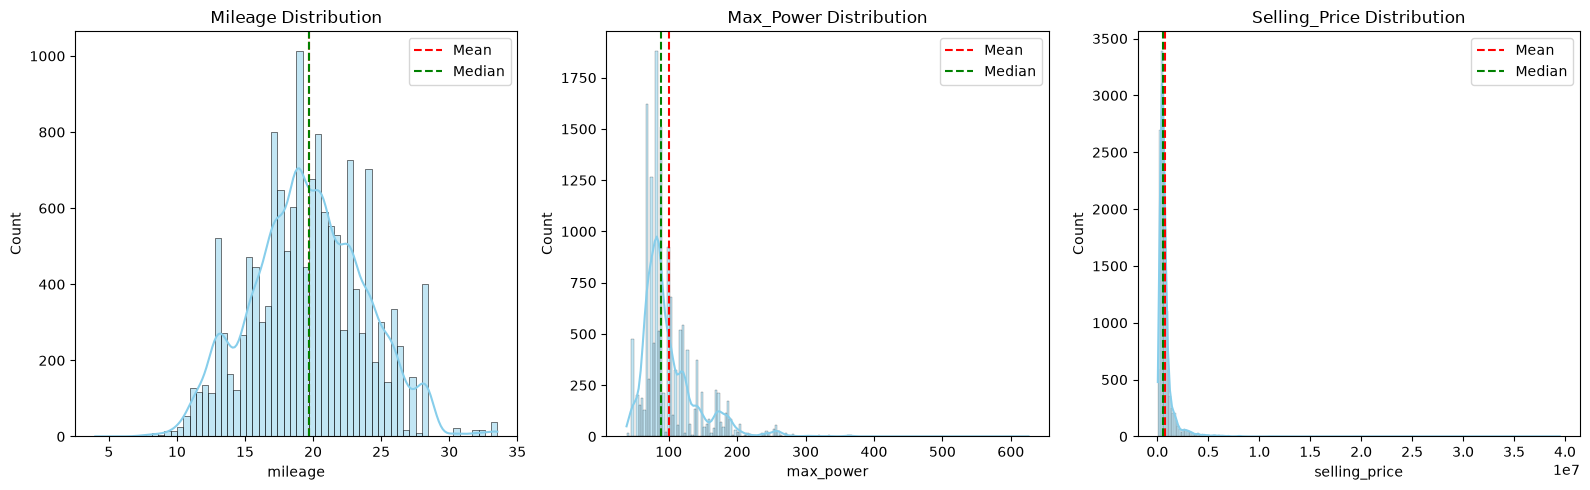

,Feature,Mean,Median,Skewness
0,mileage,19.70,19.67,0.11
1,max_power,100.71,88.50,2.49
2,selling_price,774701.45,559000.00,10.11


In [41]:

import matplotlib.pyplot as plt
import seaborn as sns

# Numerical features to visualize
features = [
    "mileage",
    "max_power",
    "selling_price"
]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for i, feature in enumerate(features):

    sns.histplot(
        cars_practice[feature].dropna(),
        kde=True,
        ax=axes[i],
        color="skyblue"
    )

    # Add mean reference line
    axes[i].axvline(
        cars_practice[feature].mean(),
        color="red",
        linestyle="--",
        label="Mean"
    )

    # Add median reference line
    axes[i].axvline(
        cars_practice[feature].median(),
        color="green",
        linestyle="--",
        label="Median"
    )

    axes[i].set_title(f"{feature.title()} Distribution")
    axes[i].set_xlabel(feature)
    axes[i].legend()

plt.tight_layout()
plt.show()

# Display statistics
distribution_summary = pd.DataFrame({
    "Feature": features,
    "Mean": [
        cars_practice[col].mean()
        for col in features
    ],
    "Median": [
        cars_practice[col].median()
        for col in features
    ],
    "Skewness": [
        cars_practice[col].skew()
        for col in features
    ]
})

display(distribution_summary.round(2))


#### Observation – Task 3.5

The Mileage distribution is nearly symmetric, with a mean of **19.70** and skewness of **0.11**.

Maximum Power is right-skewed, with skewness of **2.49**, while Selling Price is strongly right-skewed, with skewness of **10.11**.

Median imputation is more suitable for Maximum Power because it is less affected by extreme values. Mean imputation could also be reasonable for Mileage.

### **Task 3.6 – Apply `SimpleImputer`**

Use Scikit-Learn's `SimpleImputer` on at least one appropriate feature.

Remember the two main stages:

1. `fit` – learn the replacement statistic from the data;
2. `transform` – replace missing values using that statistic.

You may use `fit_transform()` when appropriate, but explain what it combines.

#### Apply SimpleImputer

**Objective:** Apply automated missing-value imputation using Scikit-Learn.

`SimpleImputer` replaces missing values using a selected statistical strategy.

**Steps performed:**
1. Create a copy of the practice dataset.
2. Identify numerical and categorical features.
3. Apply median imputation to numerical features.
4. Apply most-frequent imputation to categorical features.
5. Verify that no missing values remain.
6. Compare the dataset shape before and after imputation.

This task demonstrates how missing values can be handled without removing rows or useful features.

In [42]:

from sklearn.impute import SimpleImputer

# Create cleaned practice dataset
cars_cleaned = cars_practice.copy()

# Identify numerical columns
numeric_features = cars_cleaned.select_dtypes(
    include=["number"]
).columns.tolist()

# Identify categorical columns
categorical_features = cars_cleaned.select_dtypes(
    include=["object"]
).columns.tolist()

# Initialize imputers
numeric_imputer = SimpleImputer(
    strategy="median"
)

categorical_imputer = SimpleImputer(
    strategy="most_frequent"
)

# Apply median imputation
cars_cleaned[numeric_features] = (
    numeric_imputer.fit_transform(
        cars_cleaned[numeric_features]
    )
)

# Apply categorical imputation
cars_cleaned[categorical_features] = (
    categorical_imputer.fit_transform(
        cars_cleaned[categorical_features]
    )
)

# Display results
print("Missing Values Before:",
      cars_practice.isnull().sum().sum())

print("Missing Values After:",
      cars_cleaned.isnull().sum().sum())

print("\nOriginal Shape:", cars_practice.shape)

print("Cleaned Shape:", cars_cleaned.shape)

# Display learned statistics
imputation_summary = pd.DataFrame({
    "Numeric Feature": numeric_features,
    "Median Used": numeric_imputer.statistics_
})

display(imputation_summary)

print("\nRemaining Missing Values:")
display(cars_cleaned.isnull().sum())


Missing Values Before: 912
Missing Values After: 0

Original Shape: (15244, 13)
Cleaned Shape: (15244, 13)


,Numeric Feature,Median Used
0,vehicle_age,6.00
1,km_driven,50000.00
2,mileage,19.67
3,engine,1248.00
4,max_power,88.50
5,seats,5.00
6,selling_price,559000.00



Remaining Missing Values:


car_name             0
brand                0
model                0
vehicle_age          0
km_driven            0
seller_type          0
fuel_type            0
transmission_type    0
mileage              0
engine               0
max_power            0
seats                0
selling_price        0
dtype: int64

#### Observation – Task 3.6

I applied `SimpleImputer` using median imputation for numerical features and most-frequent imputation for categorical features.

All **912 missing values were successfully replaced**. The median values used for Mileage and Maximum Power were 19.67 and 88.50.

The dataset maintained its original practice shape of **15,244 rows and 13 columns**.

### **Task 3.7 – Validate the Cleaned Cars Dataset**

Compare the dataset **before and after cleaning**.

Report:

- shape;
- missing-value counts;
- duplicate counts;
- descriptive statistics for selected numeric columns.

Create at least **one visualization** supporting your comparison.

#### Validate the Cleaned Dataset

**Objective:** Verify that the imputation process was successful and examine its effect on the dataset.

I will compare the practice dataset before and after imputation to understand how cleaning affects the data.

**Steps performed:**
1. Compare rows and columns before and after imputation.
2. Check missing values and duplicates.
3. Compare the mean and median values of numerical features.
4. Visualize distributions before and after imputation.
5. Run validation checks using `assert`.
6. Save the final datasets as CSV files.

I will save the original cleaned CarDekho records separately from the artificially modified practice dataset. This ensures that the real data is not mixed with simulated missing values.

In [43]:

# Compare before and after imputation
validation = pd.DataFrame({
    "Metric": [
        "Rows",
        "Columns",
        "Missing Values",
        "Duplicate Records",
        "Mean Mileage",
        "Median Mileage",
        "Mean Maximum Power",
        "Median Maximum Power"
    ],

    "Before Imputation": [
        cars_practice.shape[0],
        cars_practice.shape[1],
        cars_practice.isnull().sum().sum(),
        cars_practice.duplicated().sum(),
        cars_practice["mileage"].mean(),
        cars_practice["mileage"].median(),
        cars_practice["max_power"].mean(),
        cars_practice["max_power"].median()
    ],

    "After Imputation": [
        cars_cleaned.shape[0],
        cars_cleaned.shape[1],
        cars_cleaned.isnull().sum().sum(),
        cars_cleaned.duplicated().sum(),
        cars_cleaned["mileage"].mean(),
        cars_cleaned["mileage"].median(),
        cars_cleaned["max_power"].mean(),
        cars_cleaned["max_power"].median()
    ]
})

display(validation.round(2))


,Metric,Before Imputation,After Imputation
0,Rows,15244.00,15244.00
1,Columns,13.00,13.00
2,Missing Values,912.00,0.00
3,Duplicate Records,0.00,0.00
4,Mean Mileage,19.70,19.70
5,Median Mileage,19.67,19.67
6,Mean Maximum Power,100.71,100.47
7,Median Maximum Power,88.50,88.50


#### Observation – Statistical Comparison

After imputation, missing values decreased from **912 to 0**, while the dataset size remained unchanged.

Mean Mileage remained 19.70 when rounded, and mean Maximum Power decreased slightly from 100.71 to 100.47. Both medians remained unchanged.

This indicates that imputation had only a small effect on the selected summary statistics.

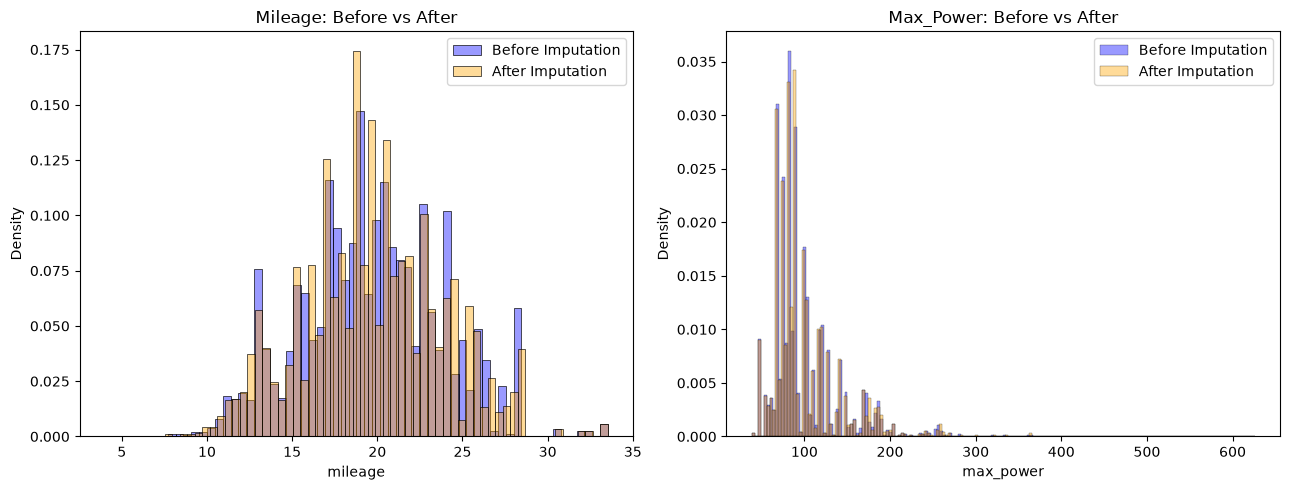

In [44]:

# Visualize distributions before and after imputation
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

features = ["mileage", "max_power"]

for i, feature in enumerate(features):

    # Original practice distribution
    sns.histplot(
        cars_practice[feature].dropna(),
        color="blue",
        alpha=0.4,
        stat="density",
        label="Before Imputation",
        ax=axes[i]
    )

    # Distribution after imputation
    sns.histplot(
        cars_cleaned[feature],
        color="orange",
        alpha=0.4,
        stat="density",
        label="After Imputation",
        ax=axes[i]
    )

    axes[i].set_title(
        f"{feature.title()}: Before vs After"
    )

    axes[i].set_xlabel(feature)
    axes[i].legend()

plt.tight_layout()
plt.show()


#### Observation – Distribution Comparison

The before-and-after histograms for Mileage and Maximum Power overlap closely.

This shows that replacing the missing values did not noticeably change the overall distribution of these two features.

In [45]:

from pathlib import Path

# Verify missing values were handled
assert cars_cleaned.isnull().sum().sum() == 0, (
    "Missing values still exist."
)

# Verify dataset dimensions were preserved
assert cars_cleaned.shape == cars_practice.shape, (
    "Dataset shape changed."
)

# Verify all original records remain in the real dataset
assert cars.isnull().sum().sum() == 0, (
    "Real CarDekho data contains missing values."
)

print("All validation checks passed!")

# Create output directory
Path("data").mkdir(exist_ok=True)

# Save the real cleaned dataset
cars.to_csv(
    "data/cardekho_cleaned.csv",
    index=False
)

# Save the practice dataset separately
cars_cleaned.to_csv(
    "data/cardekho_imputation_practice.csv",
    index=False
)

print("Real cleaned dataset saved.")
print("Imputation practice dataset saved.")


All validation checks passed!
Real cleaned dataset saved.
Imputation practice dataset saved.


#### Observation – Final Validation

All validation checks passed successfully. The cleaned practice dataset contains no missing values and retains all 15,244 records and 13 columns.

I saved `cardekho_cleaned.csv` for the original cleaned data and `cardekho_imputation_practice.csv` for the imputation experiment.

### **Task 3.8 – Cars Reflection**

Answer all questions:

1. What were the main data-quality problems?
2. How many missing values did you find?
3. What happened when you dropped rows containing missing values?
4. Why might dropping entire columns be inappropriate?
5. When is mean imputation reasonable?
6. When might median be safer than mean?
7. Where would mode imputation be appropriate?
8. How did `SimpleImputer` differ from manually calling `fillna()`?
9. Did cleaning materially change the dataset statistics?
10. Which cleaning decisions would you carry forward into an ML pipeline, and why?

### Task 3.8 – Reflection

**1. What were the main data-quality problems?**

The main issues were an unnecessary index column and 167 duplicate records. The original dataset contained no missing values.

**2. How many missing values did you find?**

The original dataset had zero missing values. I introduced 912 missing values in a separate practice dataset to demonstrate imputation.

**3. What happened when you dropped rows containing missing values?**

The dataset decreased from 15,244 to 14,351 rows. This removed 893 records containing missing values.

**4. Why might dropping entire columns be inappropriate?**

Dropping columns reduced the dataset from 13 to 10 features. This removed useful information such as Mileage, Maximum Power, and Fuel Type.

**5. When is mean imputation reasonable?**

Mean imputation is suitable for numerical data that is approximately symmetric and does not contain influential extreme values. In my dataset, Mileage was nearly symmetric.

**6. When might median be safer than mean?**

Median is safer for skewed data because it is less affected by extreme values. Maximum Power had a skewness of 2.49, making median imputation a reasonable choice.

**7. Where would mode imputation be appropriate?**

Mode imputation is useful for categorical features such as `fuel_type`, `seller_type`, and `transmission_type`. In my practice dataset, Petrol was the most common fuel type.

**8. How did SimpleImputer differ from fillna()?**

`fillna()` directly replaces missing values, while `SimpleImputer` learns replacement statistics using `fit()` and applies them using `transform()`. This makes it useful in machine learning pipelines.

**9. Did cleaning materially change the dataset statistics?**

After imputation, the mean Mileage remained 19.70 when rounded, while the mean Maximum Power decreased from 100.71 to 100.47. The medians remained unchanged.

The histograms also showed similar overall distributions before and after imputation. Therefore, the imputation process had only a small effect on the selected summary statistics.

**10. Which cleaning decisions would you carry forward into an ML pipeline, and why?**

I would remove unnecessary columns, investigate duplicates, check for invalid values, and apply suitable imputation methods. I would also fit imputers on training data only to avoid data leakage.

### Conclusion

This exercise helped me understand how to inspect, clean, and validate real-world data. I removed 167 duplicate rows and successfully handled 912 simulated missing values using median and mode imputation.

The final practice dataset contained 15,244 rows and 13 columns with no missing values. I learned how to improve data quality while preserving useful information for future machine learning tasks.

# **Section 4 – Outlier Detection (Diabetes Dataset)**

## **Learning Topic: Outlier Detection and Treatment**

An **outlier** is an observation that differs substantially from most of the data. Outliers can result from measurement errors, data-entry problems, unusual but legitimate cases, or genuinely rare events.

Outliers matter because they can affect:

- means and standard deviations;
- correlations;
- regression coefficients;
- distance-based algorithms;
- scaling and normalization;
- model evaluation.

**Important:** Detecting an outlier does **not** automatically mean it should be deleted. You must justify treatment in the context of the data.

## **Getting the Diabetes Dataset from the Internet**

For this section, use the **Pima Indians Diabetes** CSV commonly used in introductory machine-learning exercises. The expected version has **768 observations** and these nine columns:

`Pregnancies`, `Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`, `DiabetesPedigreeFunction`, `Age`, and `Outcome`.

### Recommended method — download in your browser

A public CSV copy is available here:

`https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv`

1. Open the address above in a browser.
2. Save the file as **`diabetes.csv`**.
3. Place it in your project's **`data`** folder.
4. Load the local copy:

```python
diabetes = pd.read_csv("./data/diabetes.csv")
```

### Optional Python-assisted download

```python
from pathlib import Path
import pandas as pd

Path("data").mkdir(exist_ok=True)

url = "https://raw.githubusercontent.com/npradaschnor/Pima-Indians-Diabetes-Dataset/master/diabetes.csv"
diabetes = pd.read_csv(url)
diabetes.to_csv("./data/diabetes.csv", index=False)
```

### Verify before continuing

Run:

```python
diabetes.shape
diabetes.head()
diabetes.columns
```

For the expected file, the shape should be `(768, 9)` and the columns should match the list above.

### Important data-quality warning

In this dataset, some physiological variables contain **zero values** that may represent unavailable or invalid measurements rather than plausible measurements. Do not automatically treat every zero as an outlier or delete it. Inspect the variable meaning first, document your decision, and keep the focus of this section on comparing the required outlier-detection methods.

> **Dataset-name warning:** UCI also hosts a dataset simply called **Diabetes**, but it is a different time-series dataset. For this particular lab, use the nine-column Pima-style CSV described above so your work matches the assignment.

### Dataset Description – Diabetes Prediction Dataset

For this section, we selected the **Diabetes Prediction Dataset** instead of the original Pima Indians Diabetes Dataset, following our professor's instruction to use a different dataset.

The dataset contains approximately **100,000 records and 9 columns** with information about individuals, including their age, health conditions, and diabetes status.

**Main features in the dataset:**

- **gender:** Gender of the individual.
- **age:** Age of the individual.
- **hypertension:** Indicates whether the individual has high blood pressure.
- **heart_disease:** Indicates whether the individual has heart disease.
- **smoking_history:** Smoking habits of the individual.
- **bmi:** Body Mass Index, which relates weight to height.
- **HbA1c_level:** A measure of average blood sugar levels over the past 2–3 months.
- **blood_glucose_level:** Blood glucose measurement.
- **diabetes:** Indicates whether the individual has diabetes (0 = No, 1 = Yes).

**Purpose of this analysis:**

The objective is to identify and analyze outliers in numerical features such as age, BMI, HbA1c level, and blood glucose level. We will use box plots, scatter plots, Z-Score, and Interquartile Range (IQR) methods to detect unusual values and examine how they affect the dataset.

We will also determine whether these values should be retained or treated, since an unusual medical measurement does not necessarily indicate incorrect data.

**Dataset Source:** [Diabetes Prediction Dataset – Kaggle](https://www.kaggle.com/datasets/iammustafatz/diabetes-prediction-dataset)

### **Task 4.1 – Load and Explore the Diabetes Dataset**

1. Load the Diabetes dataset from your data folder.
2. Display shape, columns, data types, and descriptive statistics.
3. Identify the numeric features you will examine for outliers.
4. Check for missing or obviously invalid values before outlier analysis.

In [46]:
# Task 4.1 - Load and inspect the alternative Diabetes dataset
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

file_path = Path("data/diabetes_prediction_dataset.csv")
if not file_path.is_file():
    raise FileNotFoundError(
        f"Dataset not found: {file_path}. Download the CSV using the link "
        "in the Markdown cell above and place it in your project data/ folder."
    )

diabetes = pd.read_csv(file_path)
print("Shape (rows, columns):", diabetes.shape)
print("Columns:", diabetes.columns.tolist())
print("\nData types:\n", diabetes.dtypes)
print("\nFirst five rows:")
display(diabetes.head())

numeric_features = ["age", "bmi", "HbA1c_level", "blood_glucose_level"]
required = numeric_features + ["diabetes"]
missing_columns = [column for column in required if column not in diabetes.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing required columns: {missing_columns}")

# Convert selected measurements safely to numeric values.
for column in numeric_features:
    diabetes[column] = pd.to_numeric(diabetes[column], errors="coerce")

print("\nMissing values per column:\n", diabetes.isna().sum())
print("\nRows with BMI <= 0:", int((diabetes["bmi"] <= 0).sum()))
print("\nDescriptive statistics for measured variables:")
display(diabetes[numeric_features].describe().T)


Shape (rows, columns): (100000, 9)
Columns: ['gender', 'age', 'hypertension', 'heart_disease', 'smoking_history', 'bmi', 'HbA1c_level', 'blood_glucose_level', 'diabetes']

Data types:
 gender                  object
age                    float64
hypertension             int64
heart_disease            int64
smoking_history         object
bmi                    float64
HbA1c_level            float64
blood_glucose_level      int64
diabetes                 int64
dtype: object

First five rows:


,gender,age,hypertension,heart_disease,smoking_history,bmi,HbA1c_level,blood_glucose_level,diabetes
0,Female,80.0,0,1,never,25.19,6.6,140,0
1,Female,54.0,0,0,No Info,27.32,6.6,80,0
2,Male,28.0,0,0,never,27.32,5.7,158,0
3,Female,36.0,0,0,current,23.45,5.0,155,0
4,Male,76.0,1,1,current,20.14,4.8,155,0



Missing values per column:
 gender                 0
age                    0
hypertension           0
heart_disease          0
smoking_history        0
bmi                    0
HbA1c_level            0
blood_glucose_level    0
diabetes               0
dtype: int64

Rows with BMI <= 0: 0

Descriptive statistics for measured variables:


,count,mean,std,min,25%,50%,75%,max
age,100000.0,41.885856,22.516840,0.08,24.00,43.00,60.00,80.00
bmi,100000.0,27.320767,6.636783,10.01,23.63,27.32,29.58,95.69
HbA1c_level,100000.0,5.527507,1.070672,3.50,4.80,5.80,6.20,9.00
blood_glucose_level,100000.0,138.058060,40.708136,80.00,100.00,140.00,159.00,300.00


### **Task 4.2 – Box Plot Method**

Create box plots for selected numeric features.

Use the plots to:

- identify observations outside the whiskers;
- compare which variables appear to contain more extreme values;
- explain what the box, median, quartiles, and whiskers represent.

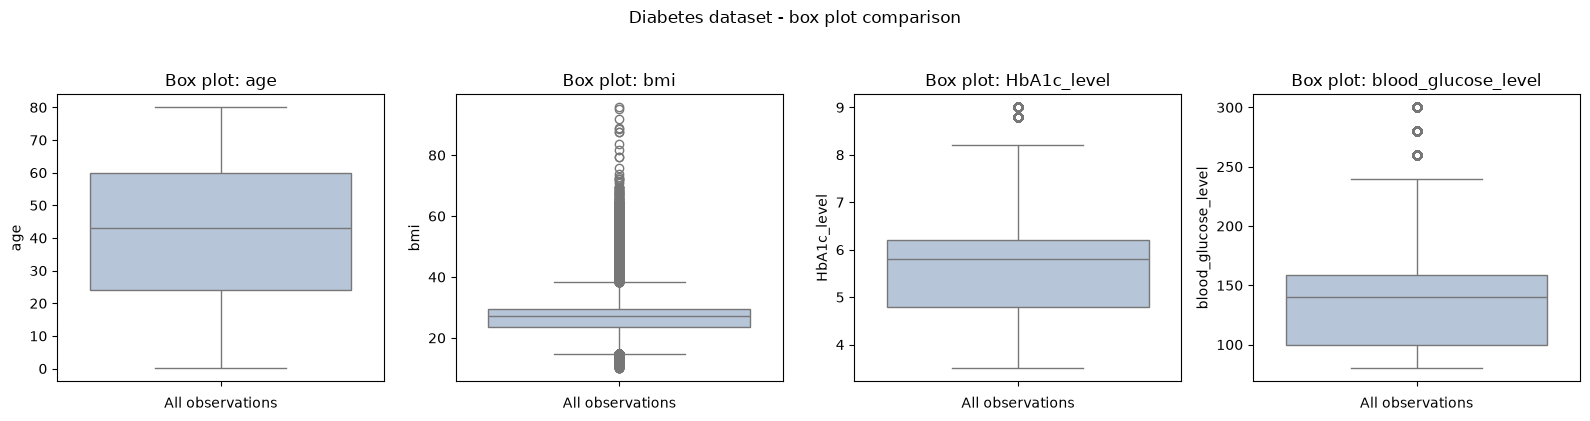

In [47]:
# Task 4.2 - Box plots for continuous numeric measurements
fig, axes = plt.subplots(1, len(numeric_features), figsize=(16, 4))
for ax, column in zip(axes, numeric_features):
    sns.boxplot(y=diabetes[column], ax=ax, color="lightsteelblue")
    ax.set_title(f"Box plot: {column}")
    ax.set_xlabel("All observations")
    ax.set_ylabel(column)
plt.suptitle("Diabetes dataset - box plot comparison", y=1.04)
plt.tight_layout()
plt.show()


### **Task 4.3 – Scatter Plot Method**

Create at least one scatter plot using two meaningful numeric features.

Use the plot to identify observations that appear isolated from the main cluster of data.

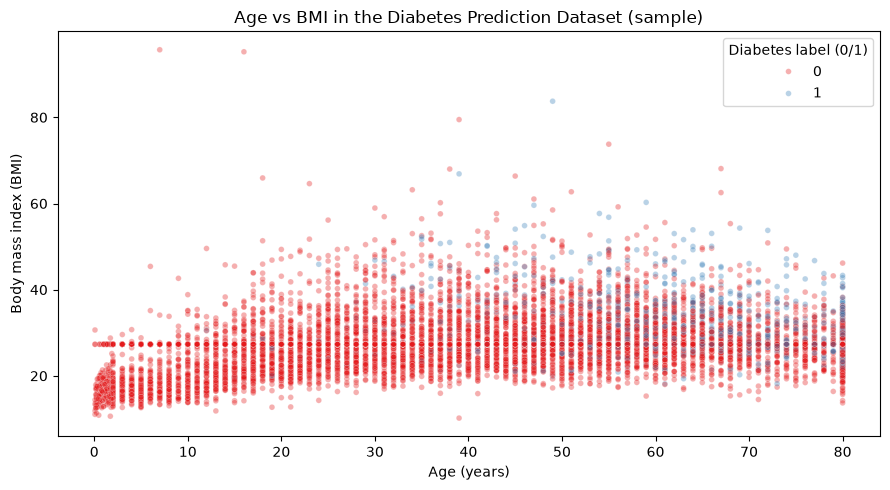

In [48]:
# Task 4.3 - Scatter plot: age compared with BMI
# Sampling makes the visualization readable; the statistical checks use all rows.
plot_data = diabetes[["age", "bmi", "diabetes"]].dropna()
plot_data = plot_data.sample(n=min(10000, len(plot_data)), random_state=42)

plt.figure(figsize=(9, 5))
sns.scatterplot(
    data=plot_data, x="age", y="bmi", hue="diabetes",
    alpha=0.35, s=17, palette="Set1"
)
plt.title("Age vs BMI in the Diabetes Prediction Dataset (sample)")
plt.xlabel("Age (years)")
plt.ylabel("Body mass index (BMI)")
plt.legend(title="Diabetes label (0/1)")
plt.tight_layout()
plt.show()


### **Task 4.4 – Z-Score Method**

For a numeric feature, calculate:

\[
z = \frac{x - \mu}{\sigma}
\]

Use the conventional threshold:

\[
|z| > 3
\]

to flag potential outliers.

Report the number of observations identified.

In [49]:
# Task 4.4 - Z-Score rule for BMI: absolute Z-Score > 3
feature = "bmi"
bmi = diabetes[feature]
mean_bmi = bmi.mean()
std_bmi = bmi.std(ddof=0)  # Population standard deviation
if std_bmi == 0 or pd.isna(std_bmi):
    raise ValueError("BMI cannot be evaluated with Z-Scores: no variability.")

bmi_zscores = (bmi - mean_bmi) / std_bmi
z_outliers = bmi_zscores.abs() > 3

print(f"Mean BMI: {mean_bmi:.3f}")
print(f"Standard deviation of BMI: {std_bmi:.3f}")
print("Z-Score threshold: |z| > 3")
print("Z-Score outliers in BMI:", int(z_outliers.sum()))
print("Outlier percentage:", round(z_outliers.mean() * 100, 2), "%")
display(diabetes.loc[z_outliers, ["age", "bmi", "HbA1c_level", "blood_glucose_level"]].head())


Mean BMI: 27.321
Standard deviation of BMI: 6.637
Z-Score threshold: |z| > 3
Z-Score outliers in BMI: 1294
Outlier percentage: 1.29 %


,age,bmi,HbA1c_level,blood_glucose_level
11,54.0,54.70,6.0,100
39,34.0,56.43,6.2,200
59,67.0,63.48,8.8,155
93,38.0,55.61,6.5,130
98,30.0,50.13,6.0,100


Task 4.4 – Talking Points: Z-Score Method

We applied the Z-Score method to BMI using a threshold of |z| > 3.

The method identified 1,294 potential outliers, representing 1.29% of the dataset.

This method helps identify observations that are unusually far from the mean based on standard deviation.

### **Task 4.5 – Interquartile Range (IQR) Method**

Calculate:

\[
IQR = Q3 - Q1
\]

Then calculate:

\[
Lower\ Bound = Q1 - 1.5(IQR)
\]

\[
Upper\ Bound = Q3 + 1.5(IQR)
\]

Identify observations outside those bounds and report the outlier count.

In [50]:
# Task 4.5 - IQR method for BMI
q1 = bmi.quantile(0.25)
q3 = bmi.quantile(0.75)
iqr = q3 - q1
lower_bound = q1 - 1.5 * iqr
upper_bound = q3 + 1.5 * iqr

iqr_outliers = (bmi < lower_bound) | (bmi > upper_bound)
print(f"BMI Q1: {q1:.3f}")
print(f"BMI Q3: {q3:.3f}")
print(f"BMI IQR (Q3 - Q1): {iqr:.3f}")
print(f"Lower bound: {lower_bound:.3f}")
print(f"Upper bound: {upper_bound:.3f}")
print("IQR outliers in BMI:", int(iqr_outliers.sum()))
print("Outlier percentage:", round(iqr_outliers.mean() * 100, 2), "%")
display(diabetes.loc[iqr_outliers, ["age", "bmi", "HbA1c_level", "blood_glucose_level"]].head())


BMI Q1: 23.630
BMI Q3: 29.580
BMI IQR (Q3 - Q1): 5.950
Lower bound: 14.705
Upper bound: 38.505
IQR outliers in BMI: 7086
Outlier percentage: 7.09 %


,age,bmi,HbA1c_level,blood_glucose_level
11,54.0,54.70,6.0,100
24,4.0,13.99,4.0,140
39,34.0,56.43,6.2,200
59,67.0,63.48,8.8,155
93,38.0,55.61,6.5,130


Task 4.5 – Talking Points: IQR Method

We applied the IQR method to BMI using the first and third quartiles.

The calculated lower and upper boundaries were 14.705 and 38.505.

The method identified 7,086 potential outliers, representing 7.09% of the dataset.

IQR is less sensitive to extreme values because it uses quartiles instead of the mean and standard deviation.

### **Task 4.6 – Compare Detection Methods**

Create a small comparison showing the number of potential outliers identified by:

- Box Plot / IQR interpretation
- Z-Score
- IQR rule

Explain why the methods may identify different observations.

In [51]:
# Task 4.6 - Compare detection rules for the SAME variable (BMI)
# A conventional box plot uses the same 1.5 * IQR whisker convention.
method_comparison = pd.DataFrame({
    "Detection method": ["Box-plot whisker rule (BMI)", "Z-Score |z| > 3 (BMI)", "IQR 1.5 rule (BMI)"],
    "Flagged observations": [int(iqr_outliers.sum()), int(z_outliers.sum()), int(iqr_outliers.sum())],
})
method_comparison["Percent of dataset"] = (
    method_comparison["Flagged observations"] / len(diabetes) * 100
).round(2)
display(method_comparison)

print("Flagged by both Z-Score and IQR:", int((z_outliers & iqr_outliers).sum()))
print("Flagged by IQR only:", int((iqr_outliers & ~z_outliers).sum()))
print("Flagged by Z-Score only:", int((z_outliers & ~iqr_outliers).sum()))


,Detection method,Flagged observations,Percent of dataset
0,Box-plot whisker rule (BMI),7086,7.09
1,Z-Score |z| > 3 (BMI),1294,1.29
2,IQR 1.5 rule (BMI),7086,7.09


Flagged by both Z-Score and IQR: 1294
Flagged by IQR only: 5792
Flagged by Z-Score only: 0


Task 4.6 – Talking Points: Method Comparison

The Z-Score method identified 1,294 BMI outliers, while the IQR method identified 7,086.

All 1,294 Z-Score outliers were also identified by IQR, while IQR identified an additional 5,792 observations.

This comparison shows that different methods can produce different results, so the selection of an outlier detection technique depends on the data distribution and analysis requirements.

### **Task 4.7 – Treat Outliers Carefully**

Create a cleaned copy of the dataset and remove outliers **only where you can justify doing so**.

Do not overwrite the original dataframe.

Compare before and after:

- number of rows;
- mean;
- median;
- standard deviation;
- relevant visualizations.

,Before (all observations),After (IQR-filtered comparison)
Number of rows,100000.000,92914.000
Mean BMI,27.321,26.401
Median BMI,27.320,27.320
BMI standard deviation,6.637,4.893


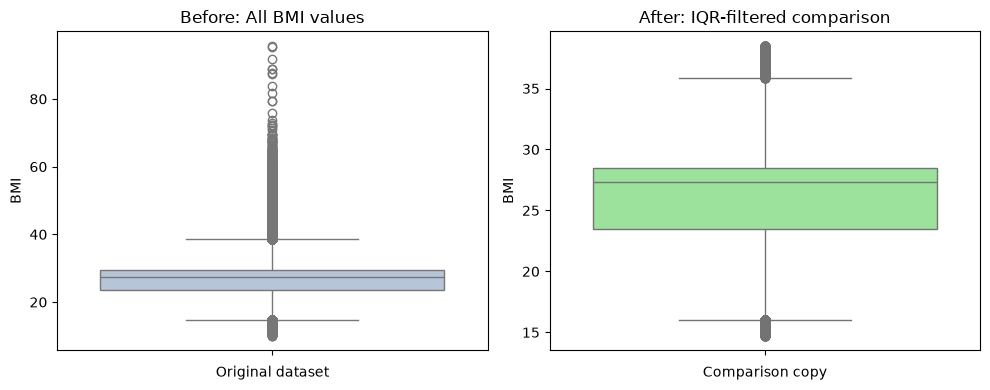

Original rows preserved: 100000
Rows flagged for investigation: 7086

Decision: Keep medically plausible extreme measurements in the retained
dataset until checked. Use the filtered copy only to illustrate how
statistical removal changes the summary and distribution.


In [52]:
# Task 4.7 - Preserve raw data and illustrate effects of removing IQR flags
# IMPORTANT: This is an educational comparison, not a claim that unusual BMIs are wrong.
diabetes_review = diabetes.copy()
diabetes_review["bmi_iqr_outlier"] = iqr_outliers

# Comparison copy only: remove BMI values flagged by the IQR rule.
diabetes_filtered = diabetes_review.loc[~diabetes_review["bmi_iqr_outlier"]].copy()

before = diabetes["bmi"]
after = diabetes_filtered["bmi"]
summary = pd.DataFrame({
    "Before (all observations)": [len(diabetes), before.mean(), before.median(), before.std()],
    "After (IQR-filtered comparison)": [len(diabetes_filtered), after.mean(), after.median(), after.std()],
}, index=["Number of rows", "Mean BMI", "Median BMI", "BMI standard deviation"])
display(summary.round(3))

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.boxplot(y=before, ax=axes[0], color="lightsteelblue")
axes[0].set_title("Before: All BMI values")
axes[0].set_ylabel("BMI")
axes[0].set_xlabel("Original dataset")
sns.boxplot(y=after, ax=axes[1], color="lightgreen")
axes[1].set_title("After: IQR-filtered comparison")
axes[1].set_ylabel("BMI")
axes[1].set_xlabel("Comparison copy")
plt.tight_layout()
plt.show()

print("Original rows preserved:", len(diabetes))
print("Rows flagged for investigation:", int(diabetes_review["bmi_iqr_outlier"].sum()))
print("\nDecision: Keep medically plausible extreme measurements in the retained")
print("dataset until checked. Use the filtered copy only to illustrate how")
print("statistical removal changes the summary and distribution.")


Task 4.7 – Talking Points: Outlier Treatment

We created a separate copy of the dataset to compare the results before and after filtering IQR-identified BMI outliers.

After filtering, the number of records decreased from 100,000 to 92,914.

The mean BMI decreased from 27.321 to 26.401, while the standard deviation decreased from 6.637 to 4.893.

We preserved the original dataset because unusual medical measurements may be valid and should not be removed without investigation.

### **Task 4.8 – Diabetes Reflection**

Answer all questions:

1. What is an outlier?
2. What are at least three possible causes of outliers?
3. Which variables showed the clearest visual outliers?
4. How many observations were flagged by the Z-Score method?
5. How many were flagged by the IQR method?
6. Why can Z-Score and IQR produce different results?
7. When should an outlier be retained?
8. When might removing an outlier be justified?
9. How did removal affect the descriptive statistics?
10. How could untreated outliers affect a downstream ML model?

### Task 4.8 – Diabetes Reflection

**1. What is an outlier?**

An outlier is a value that is significantly different from most other values in a dataset. For example, a BMI value that is much higher or lower than the majority of BMI values can be considered a potential outlier.

**2. What are at least three possible causes of outliers?**

Outliers can occur due to:
- **Data entry errors:** Incorrect values entered into the dataset.
- **Measurement errors:** Problems with equipment or the data collection process.
- **Natural variation:** Genuine but unusual measurements, such as an individual with a very high BMI.

**3. Which variables showed the clearest visual outliers?**

Based on the box plots, BMI showed the clearest outliers, with several values extending beyond the upper whisker. HbA1c level and blood glucose level also showed unusually high values. Age did not show clear outliers based on the box plot.

These values are not necessarily incorrect and should be investigated before removal.

**4. How many observations were flagged by the Z-Score method?**

Using the Z-Score method with a threshold of |z| > 3, we identified **1,294 outliers** in the BMI column, representing **1.29%** of the dataset.

This method identifies values that are more than three standard deviations away from the mean.

**5. How many observations were flagged by the IQR method?**

Using the IQR method, we identified **7,086 outliers** in the BMI column, representing **7.09%** of the dataset.

The calculated lower bound was 14.705, and the upper bound was 38.505. BMI values outside this range were considered potential outliers.

**6. Why can Z-Score and IQR produce different results?**

Z-Score identifies outliers based on the mean and standard deviation, while IQR uses the first and third quartiles.

IQR is generally less affected by extreme values, whereas Z-Score can be influenced by them.

In our analysis, Z-Score identified 1,294 outliers, while IQR identified 7,086. The IQR method identified more observations because its calculated boundaries were more restrictive for our BMI data.

**7. When should an outlier be retained?**

An outlier should be retained when it represents a valid observation rather than an error.

For example, a patient with a very high BMI may have a genuine medical condition. Removing such observations could result in losing important information.

**8. When might removing an outlier be justified?**

Removing an outlier may be justified when it is confirmed to be incorrect due to data entry or measurement errors.

For example, an impossible BMI value caused by incorrect data entry may need to be corrected or removed.

However, unusual medical measurements should not be removed without proper investigation.

**9. How did removal affect the descriptive statistics?**

After removing BMI values flagged by the IQR method in a separate comparison dataset, the number of records decreased from 100,000 to 92,914.

The descriptive statistics changed as follows:

| Statistic | Before | After |
|---|---:|---:|
| Number of records | 100,000 | 92,914 |
| Mean BMI | 27.321 | 26.401 |
| Median BMI | 27.320 | 27.320 |
| Standard deviation | 6.637 | 4.893 |

The mean and standard deviation decreased after filtering, while the median remained unchanged.

This shows that extreme values can affect the mean and standard deviation more than the median.

The original dataset was preserved, and filtering was performed only for comparison.

**10. How could untreated outliers affect a downstream ML model?**

Outliers can affect machine learning models by influencing statistical calculations, feature scaling, and model training.

For example, extremely high BMI values may affect distance-based algorithms such as K-Nearest Neighbors (KNN) and influence predictions.

However, some outliers represent genuine medical conditions and may contain useful information. Therefore, outliers should be investigated before deciding whether to remove them.

### Conclusion

In this analysis, we used box plots, scatter plots, Z-Score, and IQR methods to identify potential outliers in the Diabetes Prediction Dataset.

The IQR method identified more BMI outliers than the Z-Score method. We also observed that filtering these values reduced the mean and standard deviation.

We learned that outlier detection is an important preprocessing step, but not all outliers should be removed, especially when working with medical data.

## Replicability Check

### Objective
To verify that our notebook can be executed on different computers using the dependencies listed in `requirements.txt`.

### Testing Process
1. One group member created the GitHub repository and uploaded the project files.
2. Other group members cloned the repository onto their computers.
3. We installed the required Python libraries using `pip install -r requirements.txt`.
4. We opened the notebook in Visual Studio Code and executed our assigned sections.
5. We verified that the datasets loaded and the code produced the expected outputs.

### Testing Results
Our group collaborated using the same GitHub repository and dependency file across different computers.

The assigned sections were tested by team members using their respective environments. This helped us verify that the project files and dependencies could be shared and used across different systems.

### Conclusion
The group testing process helped us evaluate the reproducibility of the project. A complete end-to-end execution of all notebook sections should also be verified to confirm full reproducibility.